# Aprendizagem de Máquina não Supervisionado

#Entregar até dia: 04/10/2026
#Colocar o número da matrícula
#email: amvieira@pucsp.br


# Exercício sobre Métodos de Clusterização


## Introdução

Este exercício utiliza um conjunto de dados sobre a qualidade do vinho. O conjunto de dados contém diversas propriedades químicas do vinho, como acidez, açúcar, pH e teor alcoólico. Também contém uma métrica de qualidade (de 3 a 9, sendo a mais alta a melhor) e uma cor (tinto e branco). O nome do arquivo é `vinhos_dataset.csv`, disponível em https://raw.githubusercontent.com/tonyvieira/aulas_clusterizacao/refs/heads/main/vinhos_dataset.csv

Vamos comparar os resultados encontrados pelos 4 algoritmos.


## Questão 1 - Análise do dataset de treinamento e de teste

* Importe os dados do dataset de TREINAMENTO e examine as características. O arquivo está disponível em: https://raw.githubusercontent.com/tonyvieira/aulas_clusterizacao/refs/heads/main/vinhos_dataset.csv

* Quantas entradas existem para as duas cores e para a gama de qualidades? Qual a proporção de vinho de cada cor? O dataset está balanceado?

* Plote um gráfico individual por cor (histograma) considerando a qualidade e o teor alcólico de cada vinho.

* Realize quaisquer transformações e/ou escalonamentos de características apropriados. Dica: Utilize StandardScaler do sklearn.

In [1]:
import numpy as np
import itertools
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import MeanShift, estimate_bandwidth
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

np.random.seed(42)

vinhos_dataframe = pd.read_csv("https://raw.githubusercontent.com/tonyvieira/aulas_clusterizacao/refs/heads/main/vinhos_dataset.csv")



print("Vinhos Dataframe tem: "+ str(vinhos_dataframe.shape[1])+ " colunas e "+ str(vinhos_dataframe.shape[0])+ " registros")

Vinhos Dataframe tem: 13 colunas e 6497 registros


Padronização de imagens -> aprendido nas aulas de python.
No código abaixo cria-se um folder "figuras" para salvar as imagens geradas
Salva as configurações para todas as figuras ficarem com as mesmas configurações
Também cria o método "salvar" para salvar em PDF e PNG

In [2]:
from pathlib import Path

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (8, 4.5)
plt.rcParams["figure.dpi"] = 110

FIGURAS = Path("figuras")
FIGURAS.mkdir(exist_ok=True)


def salvar(fig, nome):
    """Grava a figura em PDF (entra nos slides) e PNG (fica no notebook)."""
    for ext in ("pdf", "png"):
        fig.savefig(FIGURAS / f"{nome}.{ext}", dpi=300, bbox_inches="tight")

In [3]:
vinhos_dataframe.head() #analise inicial: abrir o head do dataframe para ver o que tem dentro

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,color
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


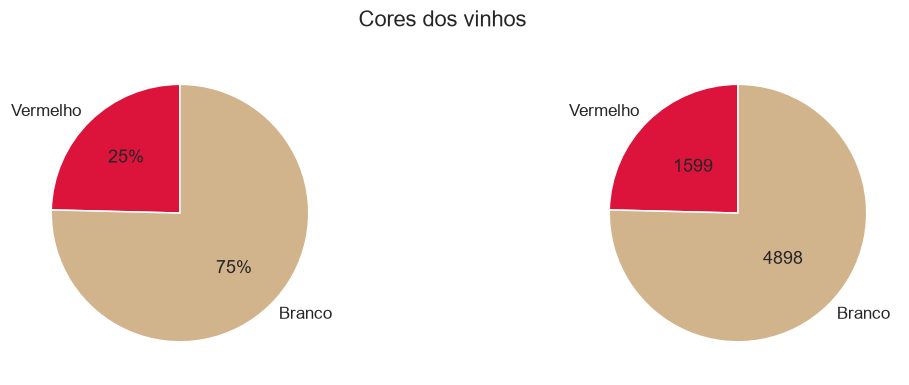

In [4]:
num_vermelho = vinhos_dataframe[vinhos_dataframe['color'] == 'red'].shape[0]
num_branco = vinhos_dataframe[vinhos_dataframe['color'] == 'white'].shape[0]

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
plt.suptitle('Cores dos vinhos')

pie = ax[0].pie(
    [num_vermelho, num_branco],
    labels=['Vermelho', 'Branco'],
    startangle=90,
    autopct='%1.f%%',
    colors=['crimson', 'tan'])


pie = ax[1].pie(
    [num_vermelho, num_branco],
    labels=['Vermelho', 'Branco'],
    startangle=90,
    colors=['crimson', 'tan'])
ax[1].pie_label(pie, labels=[num_vermelho, num_branco], distance=0.5)



plt.show()

Dataset está bem desbalanceado com 75% dos vinhos do tipo Branco.

| Cor      |   Registros   |
|----------|:-------------:|
| Vermelho |     1599      |
|  Branco  |    4898       |

Dúvida: Deixar desbalanceado ou podar vinhos brancos?


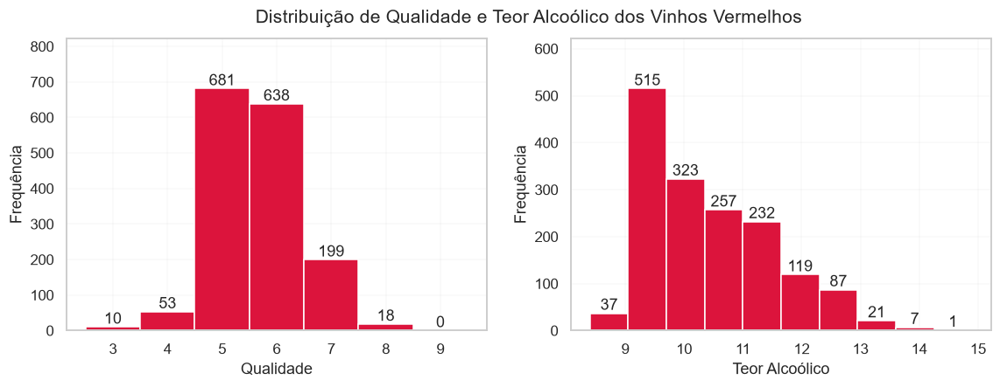

In [5]:
vinhos_vermelhos_dataframe = vinhos_dataframe[vinhos_dataframe["color"] == "red"]

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
plt.suptitle("Distribuição de Qualidade e Teor Alcoólico dos Vinhos Vermelhos", fontsize=14)
fig.subplots_adjust(left=0.1, right=0.9, top=0.9, bottom=0.1)

ax[0].hist(vinhos_vermelhos_dataframe['quality'], bins=np.arange(2.5, 10.5, 1), color="crimson")
ax[1].hist(vinhos_vermelhos_dataframe['alcohol'], bins=10, color="crimson")

ax[0].set_ylim(top=ax[0].get_ylim()[1] * 1.15)
ax[1].set_ylim(top=ax[1].get_ylim()[1] * 1.15)

ax[0].set_axisbelow(True)
ax[0].grid(True, axis="both", color="gray", alpha=0.25, linewidth=0.2)
ax[1].set_axisbelow(True)
ax[1].grid(True, axis="both", color="gray", alpha=0.25, linewidth=0.2)

ax[0].set_xlabel("Qualidade")
ax[1].set_xlabel("Teor Alcoólico")
ax[0].set_ylabel("Frequência")
ax[1].set_ylabel("Frequência")
for axis in ax:
    for container in axis.containers:
        axis.bar_label(container)

salvar(fig, "Distribuicao_Qualidade_Teor_Alcoolico_Vinhos_Vermelhos")
plt.show()


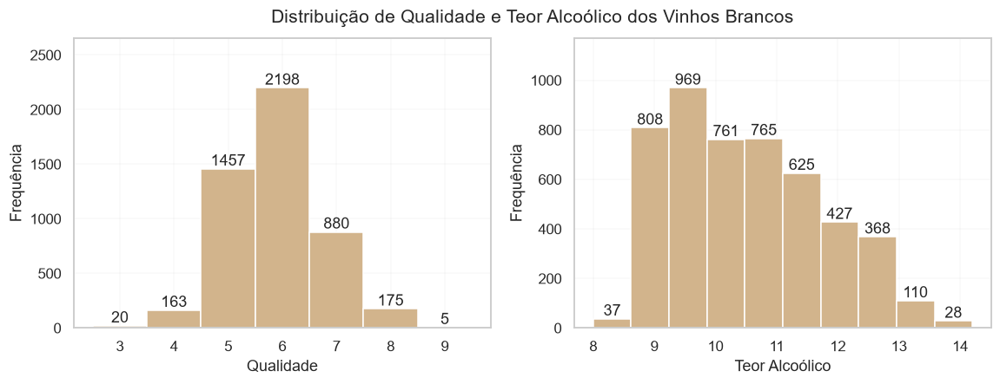

In [6]:
vinhos_brancos_dataframe = vinhos_dataframe[vinhos_dataframe["color"] == "white"]

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
plt.suptitle("Distribuição de Qualidade e Teor Alcoólico dos Vinhos Brancos", fontsize=14)
fig.subplots_adjust(left=0.1, right=0.9, top=0.9, bottom=0.1)

ax[0].hist(vinhos_brancos_dataframe['quality'], bins=np.arange(2.5, 10.5, 1), color="tan")
ax[1].hist(vinhos_brancos_dataframe['alcohol'], bins=10, color="tan")

ax[0].set_ylim(top=ax[0].get_ylim()[1] * 1.15)
ax[1].set_ylim(top=ax[1].get_ylim()[1] * 1.15)

ax[0].set_axisbelow(True)
ax[0].grid(True, axis="both", color="gray", alpha=0.25, linewidth=0.2)
ax[1].set_axisbelow(True)
ax[1].grid(True, axis="both", color="gray", alpha=0.25, linewidth=0.2)

ax[0].set_xlabel("Qualidade")
ax[1].set_xlabel("Teor Alcoólico")
ax[0].set_ylabel("Frequência")
ax[1].set_ylabel("Frequência")
for axis in ax:
    for container in axis.containers:
        axis.bar_label(container)

salvar(fig, "Distribuicao_Qualidade_Teor_Alcoolico_Vinhos_Brancos")
plt.show()


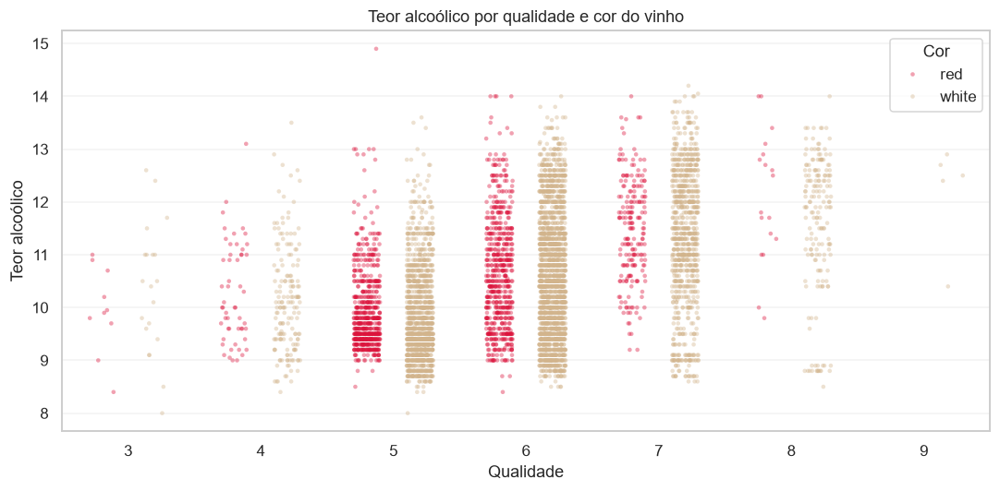

In [7]:
fig, ax = plt.subplots(figsize=(10, 5))

sns.stripplot(
    data=vinhos_dataframe,
    x="quality",
    y="alcohol",
    hue="color",
    hue_order=["red", "white"],
    palette={"red": "crimson", "white": "tan"},
    dodge=True,
    jitter=0.2,
    alpha=0.4,
    size=3,
    ax=ax
)

ax.set_title("Teor alcoólico por qualidade e cor do vinho")
ax.set_xlabel("Qualidade")
ax.set_ylabel("Teor alcoólico")
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
ax.legend(title="Cor")

plt.tight_layout()
salvar(fig, "Teor_Alcoolico_por_Qualidade_e_Cor_do_Vinho")
plt.show()


Análise dos dados:

Os dados estão desbalanceados com relação ao tipo de vinho: Tinto, Branco.

Parece haver também um desbalanceamento em relação à qualidade dos vinhos de tipo Tinto: há bastante registros de qualidades 5 e 6 de vinhos tinto mas nem tanto das do tipo 8 e 9. Pode ser pela pouca quantidade de registros a posteriori.

Normalização

In [8]:
scaler = StandardScaler()



vinhos_scaled = scaler.fit_transform(vinhos_dataframe.drop(columns=["color"]))

vinhos_scaled_dataframe = pd.DataFrame(vinhos_scaled, columns=vinhos_dataframe.drop(columns=["color"]).columns)
#vinhos_scaled_dataframe["color"] = vinhos_dataframe["color"]

vinhos_scaled_dataframe.head()


#analise depois de escalar os dados, para ver se a escala mudou e se os dados estão prontos para o clustering

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality
0,0.142473,2.188833,-2.192833,-0.744778,0.569958,-1.100140,-1.446359,1.034993,1.813090,0.193097,-0.915464,-0.937230
1,0.451036,3.282235,-2.192833,-0.597640,1.197975,-0.311320,-0.862469,0.701486,-0.115073,0.999579,-0.580068,-0.937230
2,0.451036,2.553300,-1.917553,-0.660699,1.026697,-0.874763,-1.092486,0.768188,0.258120,0.797958,-0.580068,-0.937230
3,3.073817,-0.362438,1.661085,-0.744778,0.541412,-0.762074,-0.986324,1.101694,-0.363868,0.327510,-0.580068,0.207999
4,0.142473,2.188833,-2.192833,-0.744778,0.569958,-1.100140,-1.446359,1.034993,1.813090,0.193097,-0.915464,-0.937230


## Questão 2 - KMeans

* Agora, ajuste modelos K-Means com valores de cluster variando de 1 a 30.
* Para cada modelo, armazene o número de clusters e o valor de inércia (método elbow).
* Plote o número de clusters versus a inércia. Parece haver um número ideal de clusters?
* Ajuste um modelo de agrupamento K-means com o número ideal de clusters.

* Examine os clusters contando o número de vinhos tintos e brancos em cada cluster.


In [9]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

In [10]:
ks = range(1, 31)
inercias, silhouettes = [], []
silhouette_ks = range(2, 31)

X = vinhos_scaled_dataframe[["fixed_acidity", "volatile_acidity", "citric_acid", "residual_sugar", "chlorides", "free_sulfur_dioxide", "total_sulfur_dioxide", "density", "pH", "sulphates", "alcohol", "quality"]]

for k in ks:
    km = KMeans(
        n_clusters=k,
        init='k-means++',   # inicialização inteligente
        n_init=10,           # 10 tentativas, guarda a melhor
        max_iter=300,        # máximo de iterações
        tol=1e-4,            # tolerância de convergência
        random_state=42     # reprodutibilidade
    )
    labels = km.fit_predict(X)
    inercias.append(km.inertia_)
    if k >= 2:
        silhouettes.append(silhouette_score(X, labels, random_state=42))

print("Grupos encontrados para k=2 a k=30: ", len(silhouettes))

Grupos encontrados para k=2 a k=30:  29


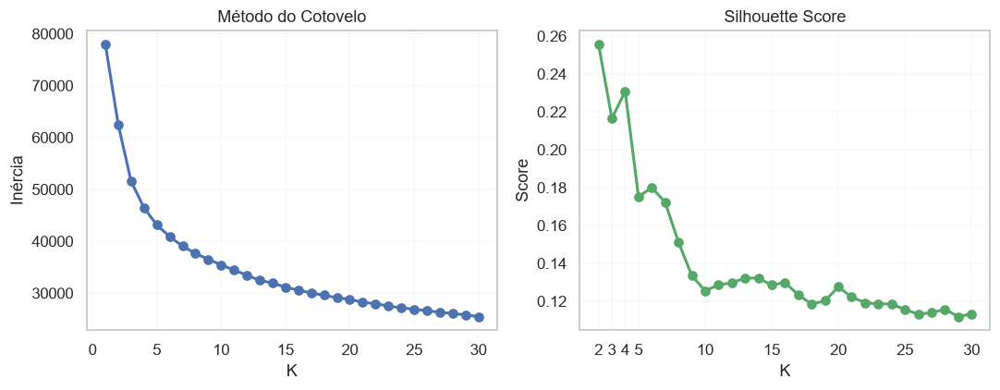

In [11]:

# Plotar diagnóstico
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.plot(ks, inercias, 'bo-', linewidth=2)
ax1.set_title('Método do Cotovelo'); ax1.set_xlabel('K'); ax1.set_ylabel('Inércia')
ax1.grid(True, axis="both", color="gray", alpha=0.25, linewidth=0.2)
ax2.plot(silhouette_ks, silhouettes, 'go-', linewidth=2)
ax2.set_xticks([2, 3, 4, 5, 10, 15, 20, 25, 30])
ax2.set_title('Silhouette Score'); ax2.set_xlabel('K'); ax2.set_ylabel('Score')
ax2.grid(True, axis="both", color="gray", alpha=0.25, linewidth=0.2)
plt.tight_layout();  salvar(fig, "KMeans_Diagnostico_Inercia_Silhouette"); plt.show()


Através do método do cotovelo e silhouette score k=2 aparenta ser o valor ideal de k. Apesar disso irei fazer k=3 e k=4 para avaliar através dos gráficos.

In [12]:
km_2 = KMeans(n_clusters=2, random_state=10)
km_2.fit(X)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",2
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",10
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](2, 12)","

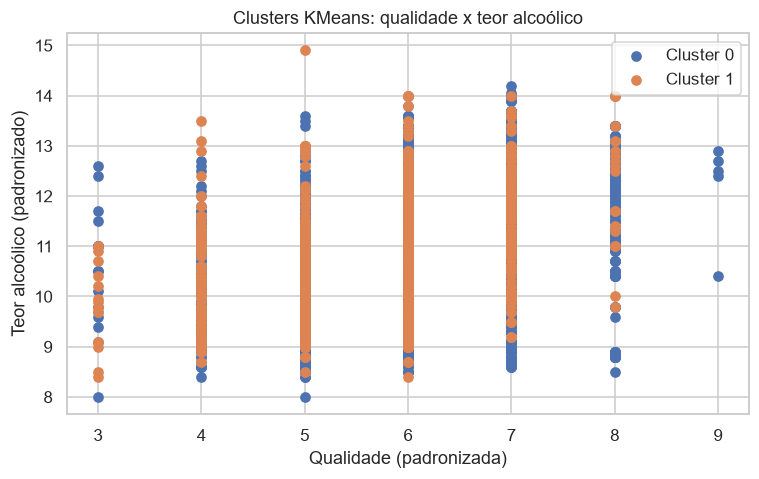

In [13]:
for label in np.unique(km_2.labels_):
    X_ = vinhos_dataframe.loc[km_2.labels_ == label]
    plt.scatter(
        X_["quality"],
        X_["alcohol"],
        label=f"Cluster {label}"
    )

plt.xlabel("Qualidade (padronizada)")
plt.ylabel("Teor alcoólico (padronizado)")
plt.title("Clusters KMeans: qualidade x teor alcoólico")
plt.legend()
plt.show()

Separar por qualidade não parece fazer sentido. Parece que existem vinhos de boa qualidade de diferentes tipos. Então vou tentar diferentes axis para vizualizar melhor os clusters.

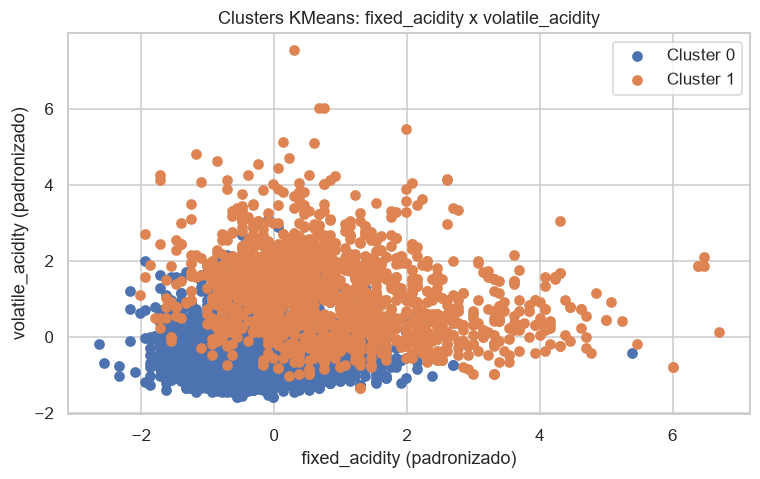

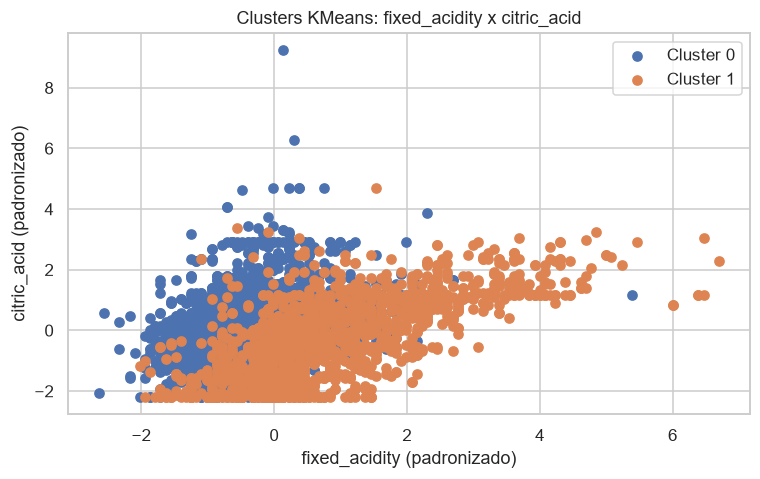

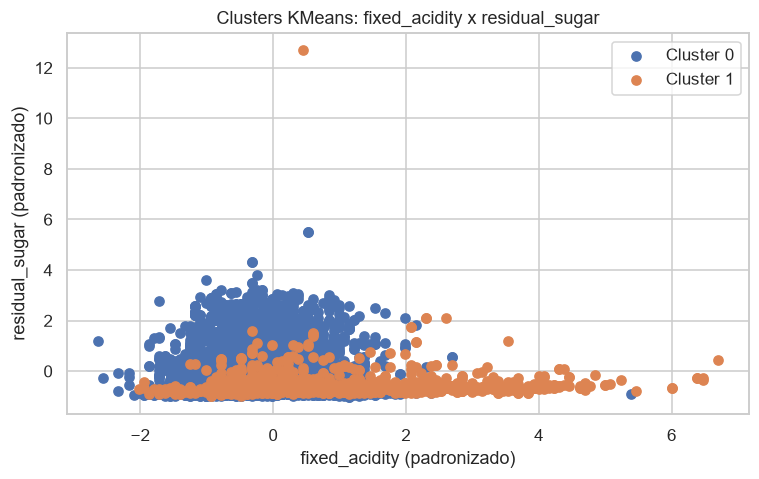

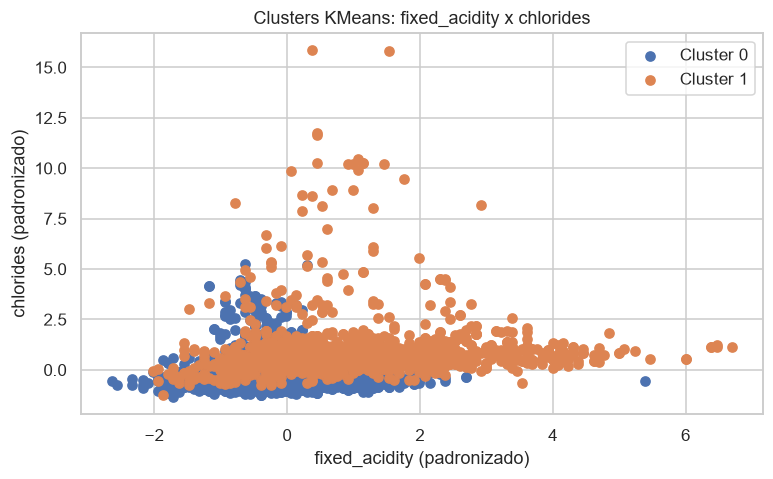

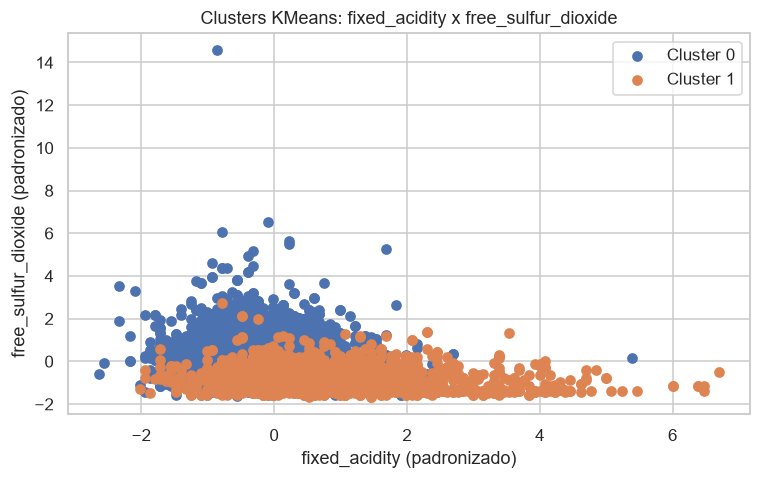

...

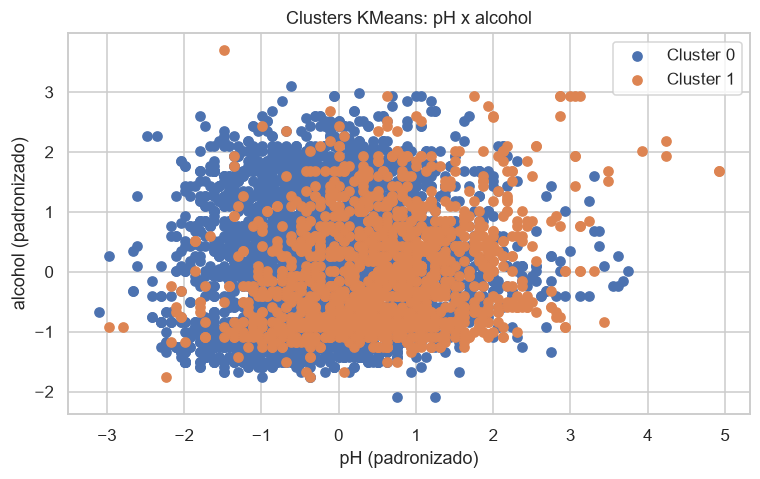

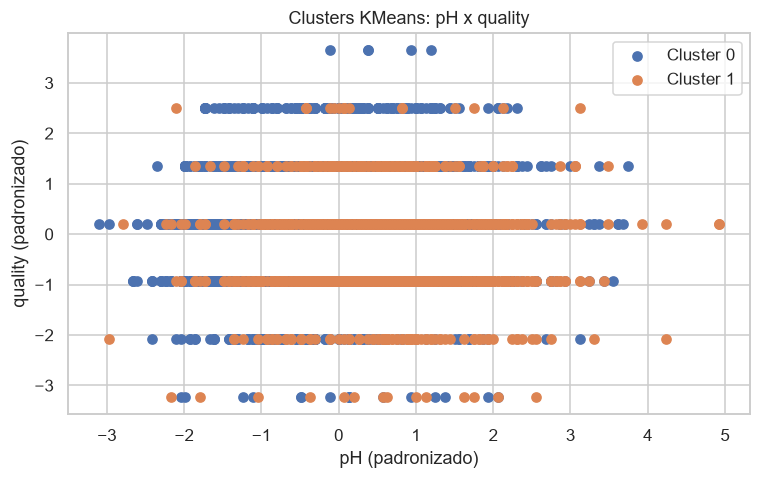

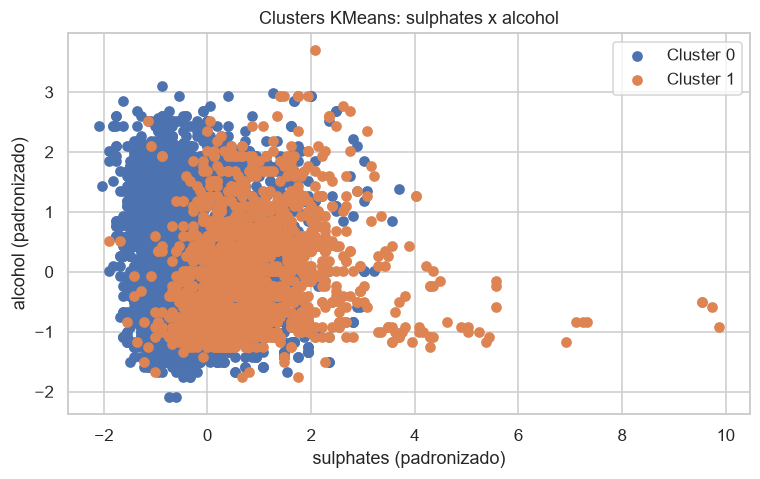

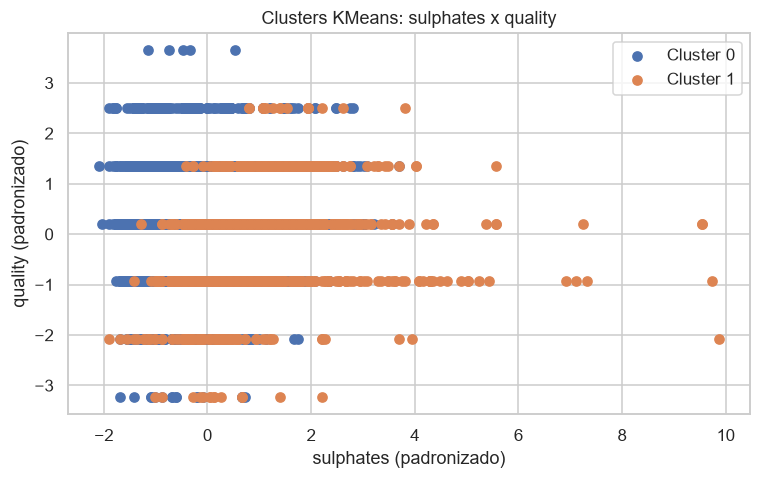

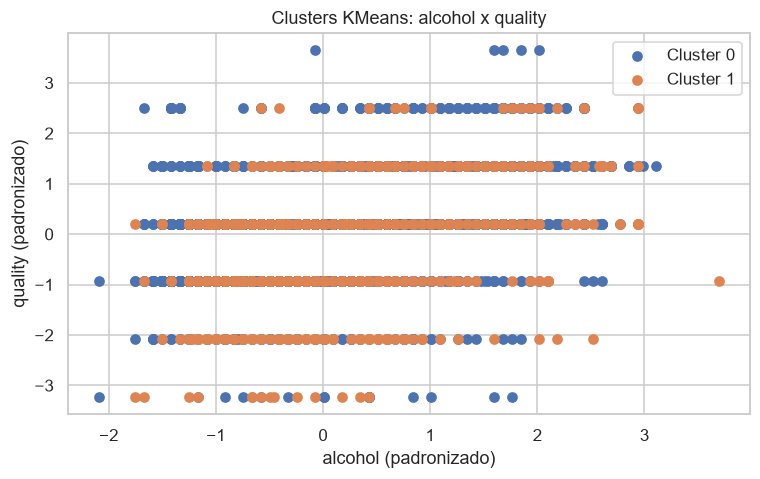

In [14]:
features = ["fixed_acidity", "volatile_acidity", "citric_acid", "residual_sugar", "chlorides", "free_sulfur_dioxide", "total_sulfur_dioxide", "density", "pH", "sulphates", "alcohol", "quality"]

graph_combinations = list(itertools.combinations(features, 2))

for combination in graph_combinations:
    
    for label in np.unique(km_2.labels_):
        X_ = X[km_2.labels_ == label]
        plt.scatter(
            X_[combination[0]],
            X_[combination[1]],
            label=f"Cluster {label}"
        )
    plt.xlabel(combination[0] + " (padronizado)")
    plt.ylabel(combination[1] + " (padronizado)")
    plt.title("Clusters KMeans: " + combination[0] + " x " + combination[1])
    plt.legend()
    plt.show()


Teor Alcólico X Total Dióxido de Enxofre parece ter a melhor vizualização em um plano 2D, onde há menos sobreposição entre os Clusters 1 e 2

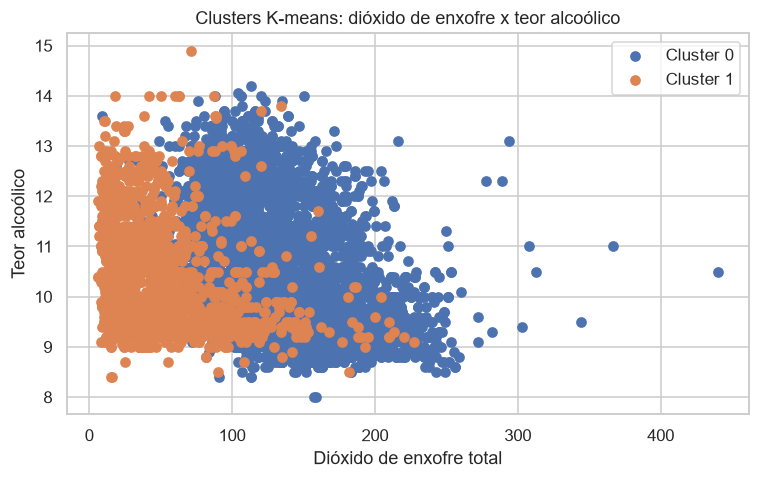

In [15]:
vinhos_clusterizados = vinhos_dataframe[
    ["total_sulfur_dioxide", "alcohol"]
].copy()

vinhos_clusterizados["cluster"] = km_2.labels_

for label in np.unique(vinhos_clusterizados["cluster"]):
    grupo = vinhos_clusterizados[
        vinhos_clusterizados["cluster"] == label
    ]

    plt.scatter(
        grupo["total_sulfur_dioxide"],
        grupo["alcohol"],
        label=f"Cluster {label}"
    )

plt.xlabel("Dióxido de enxofre total")
plt.ylabel("Teor alcoólico")
plt.title("Clusters K-means: dióxido de enxofre x teor alcoólico")
plt.legend()
salvar(fig, "2_Clusters_KMeans_Dioxido_Enxofre_x_Teor_Alcoolico")
plt.show()


Testar com k=3

In [16]:
km_3 = KMeans(n_clusters=3, random_state=10)
km_3.fit(X)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",3
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",10
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](3, 12)","

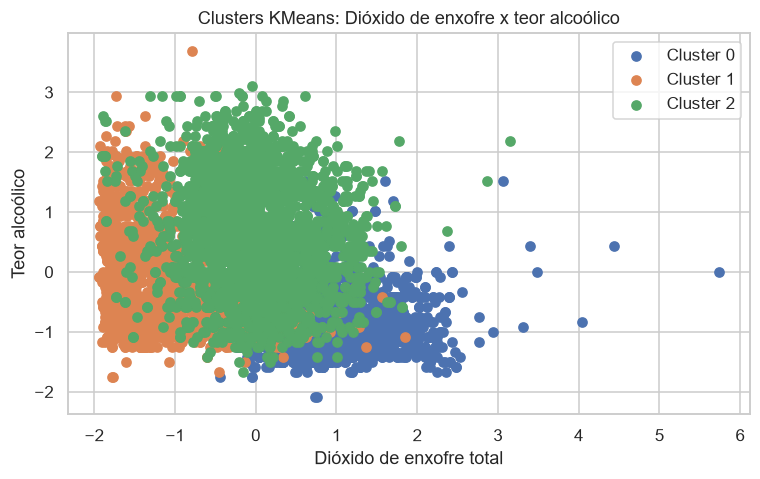

In [17]:
for label in np.unique(km_3.labels_):
    X_ = X[km_3.labels_ == label]
    plt.scatter(
        X_["total_sulfur_dioxide"],
        X_["alcohol"],
        label=f"Cluster {label}"
    )

plt.xlabel("Dióxido de enxofre total")
plt.ylabel("Teor alcoólico")
plt.title("Clusters KMeans: Dióxido de enxofre x teor alcoólico")
plt.legend()
salvar(fig, "3_Clusters_KMeans_Dioxido_Enxofre_x_Teor_Alcoolico")
plt.show()


Aparentemente ele dividiu igualmente os clusters 1 e 2 que estavam no K=2. Pode ser que tenha outra characterística em outras dimensões. Vou fazer o mesmo que fiz para o k=2

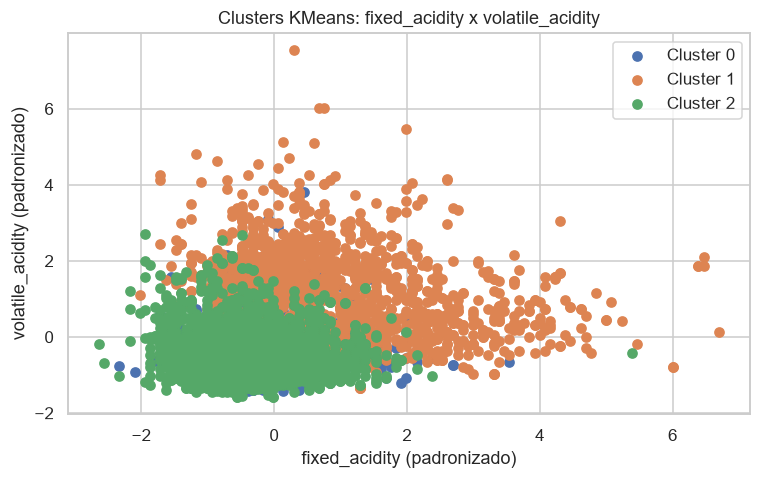

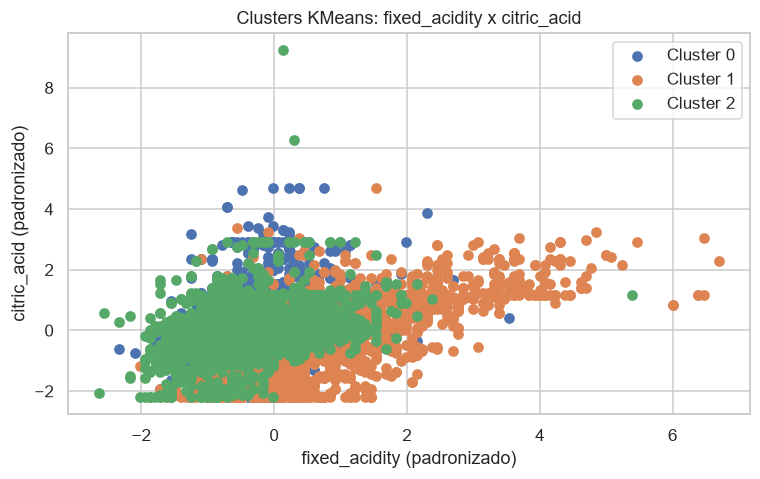

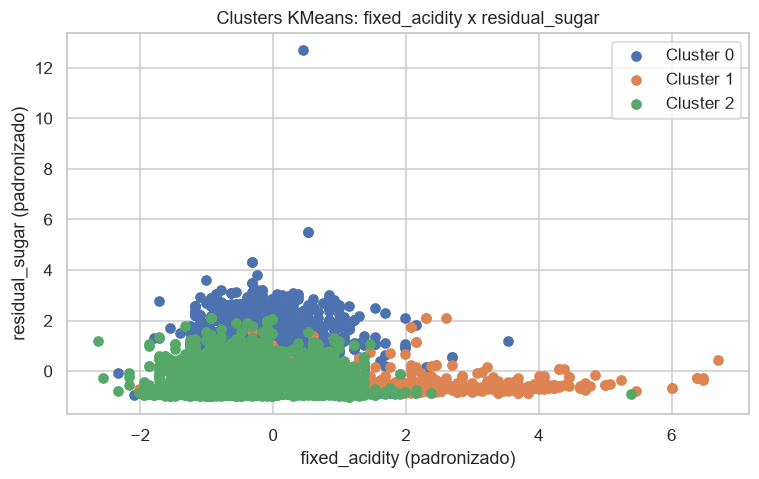

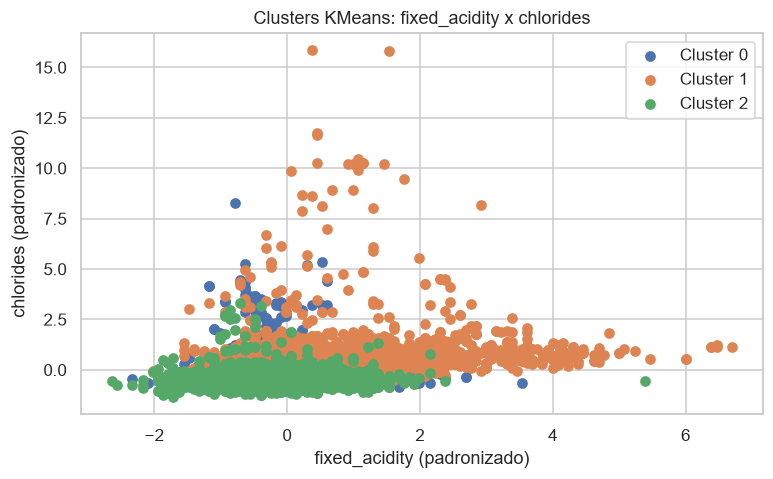

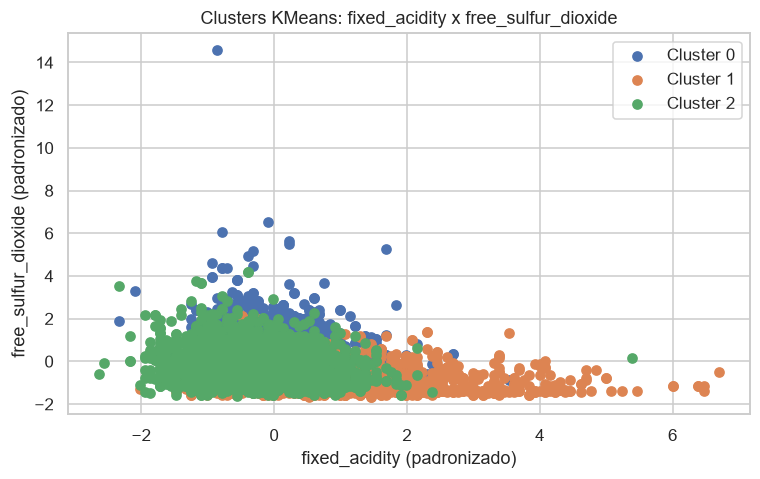

...

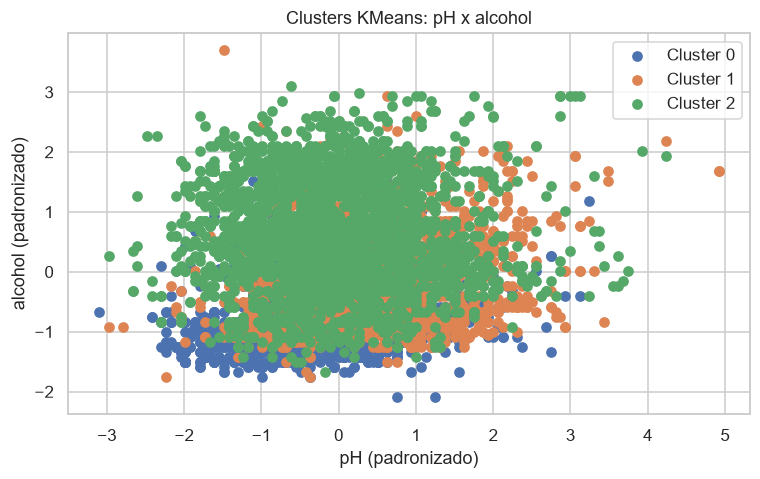

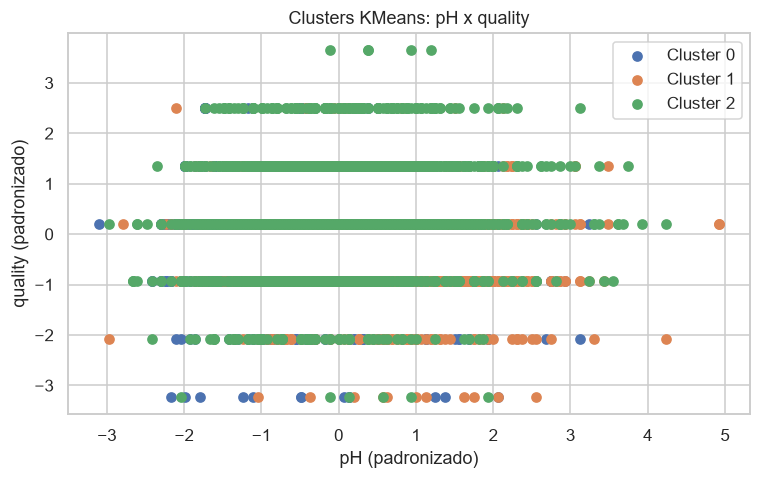

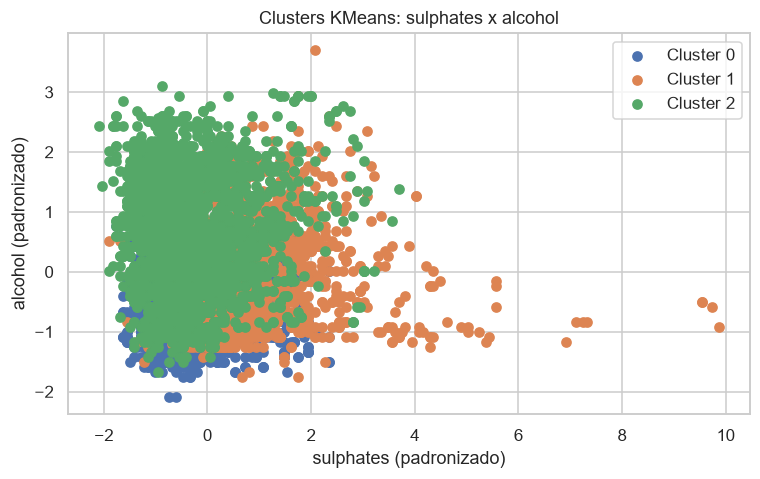

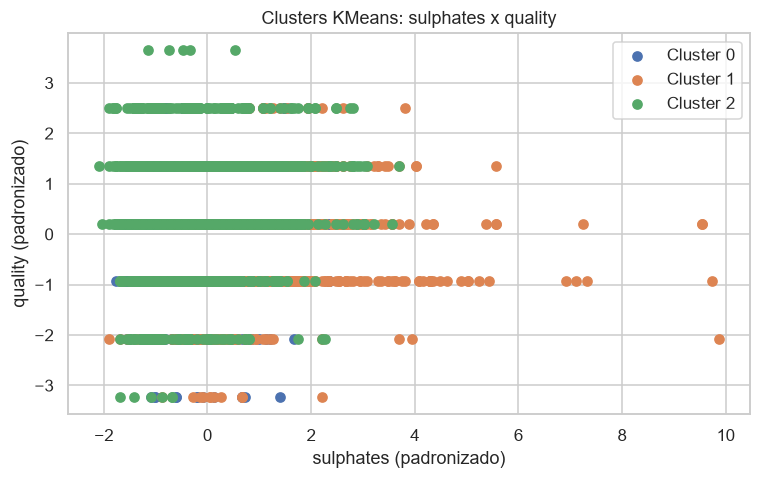

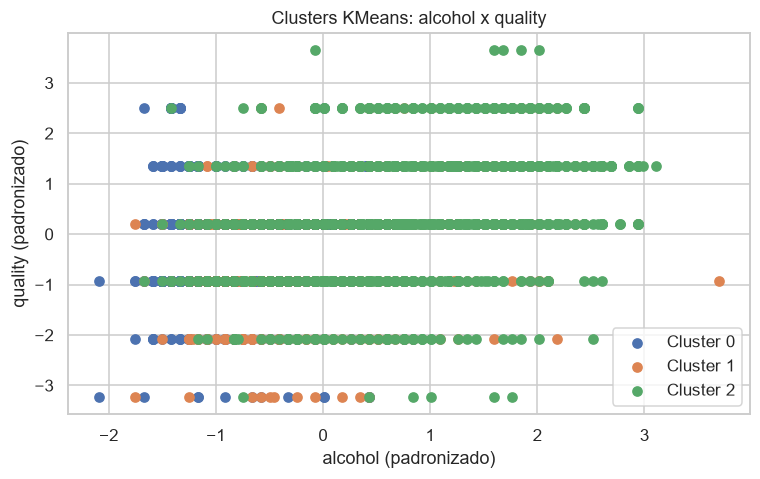

In [18]:
for combination in graph_combinations:
    
    for label in np.unique(km_3.labels_):
        X_ = X[km_3.labels_ == label]
        plt.scatter(
            X_[combination[0]],
            X_[combination[1]],
            label=f"Cluster {label}"
        )
    plt.xlabel(combination[0] + " (padronizado)")
    plt.ylabel(combination[1] + " (padronizado)")
    plt.title("Clusters KMeans: " + combination[0] + " x " + combination[1])
    plt.legend()
    plt.show()

Agora com k=4

In [19]:
km_4 = KMeans(n_clusters=4, random_state=10)
km_4.fit(X)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",4
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",10
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](4, 12)","

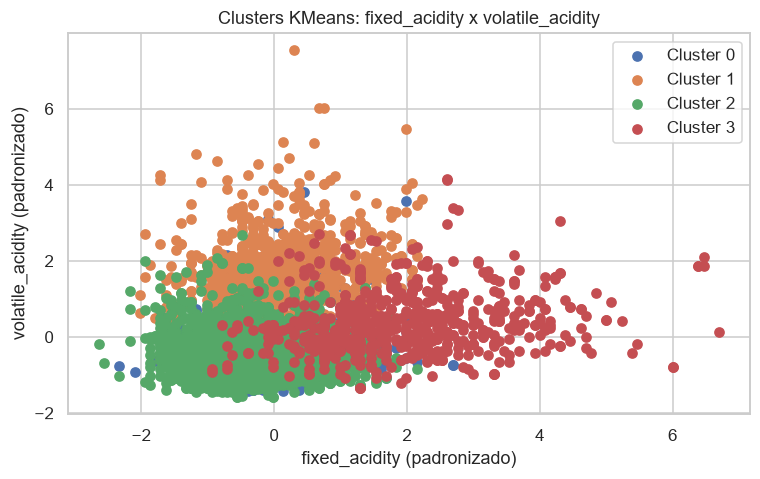

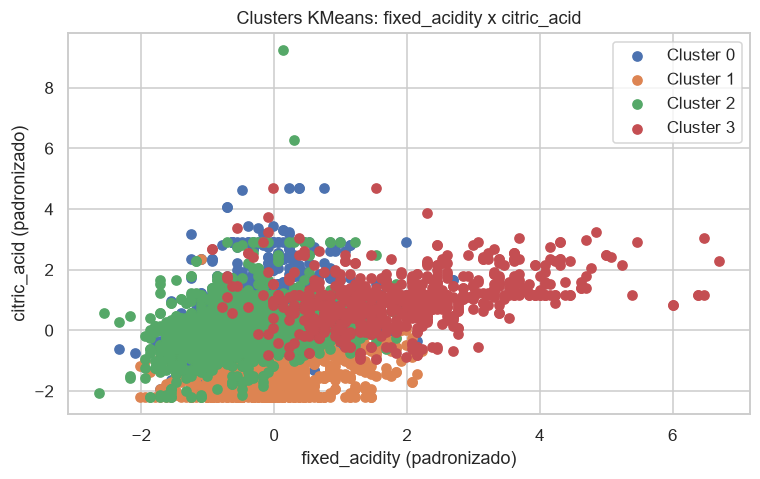

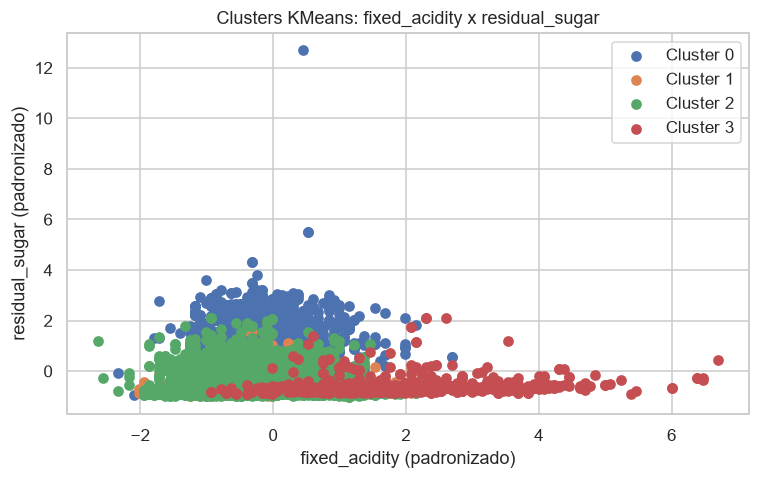

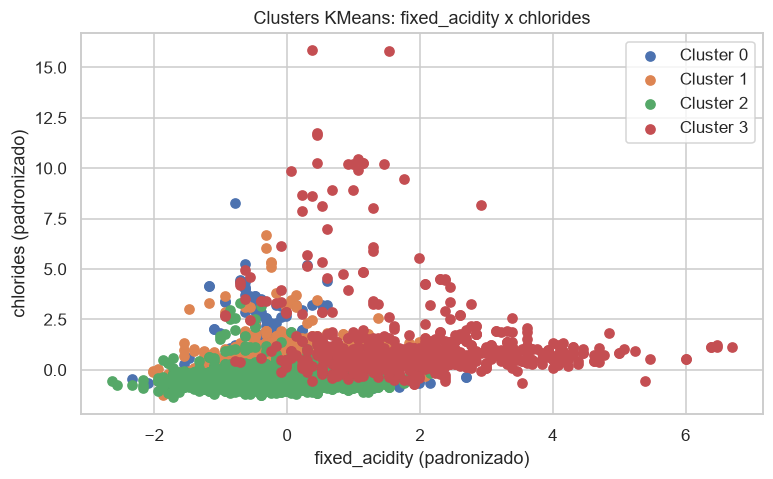

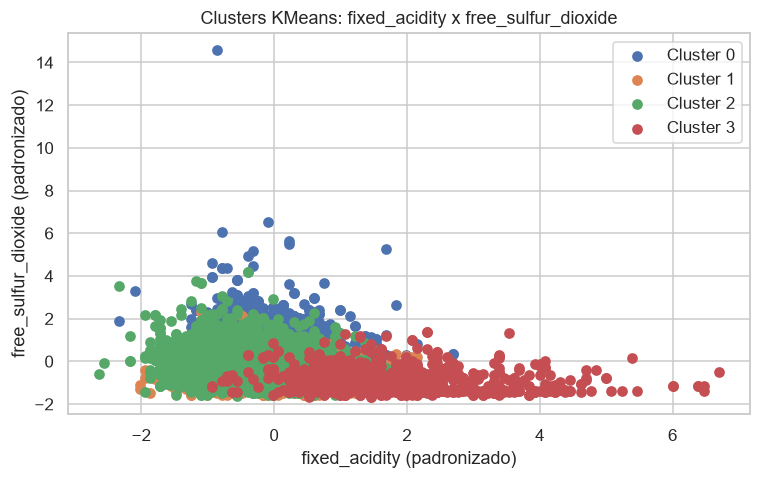

...

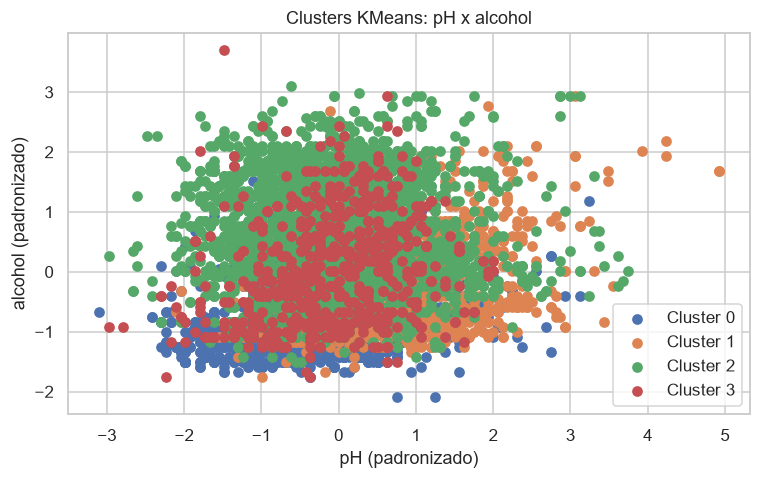

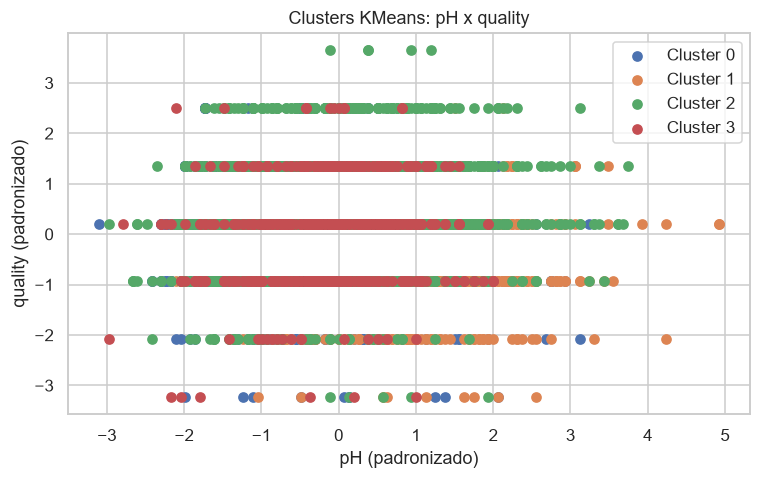

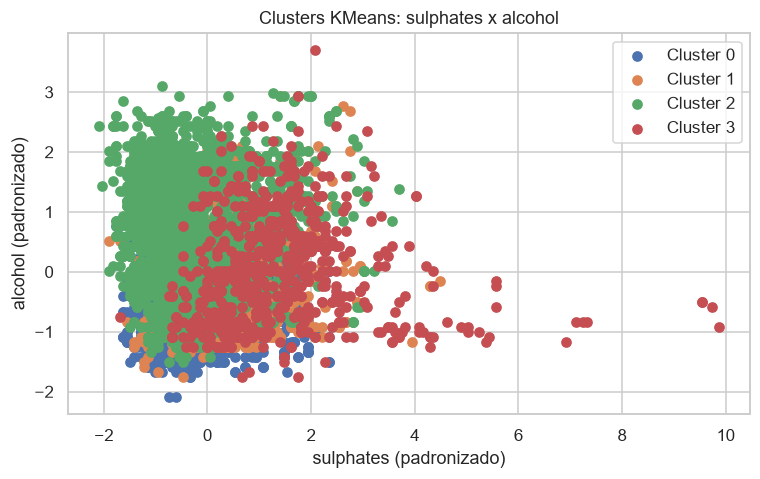

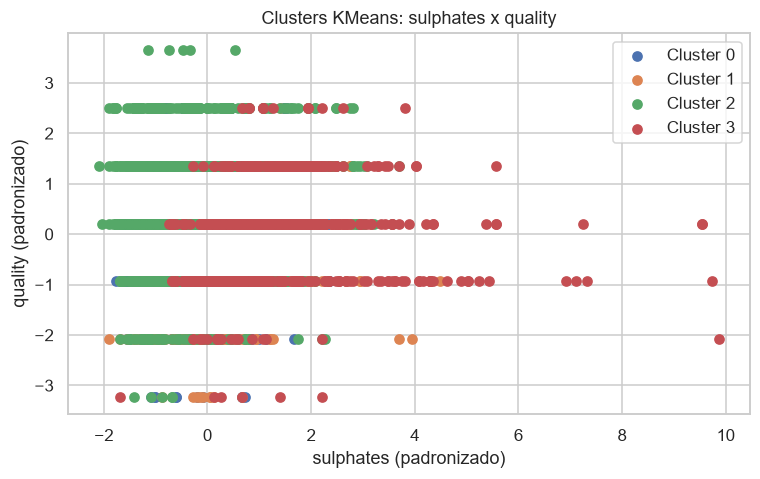

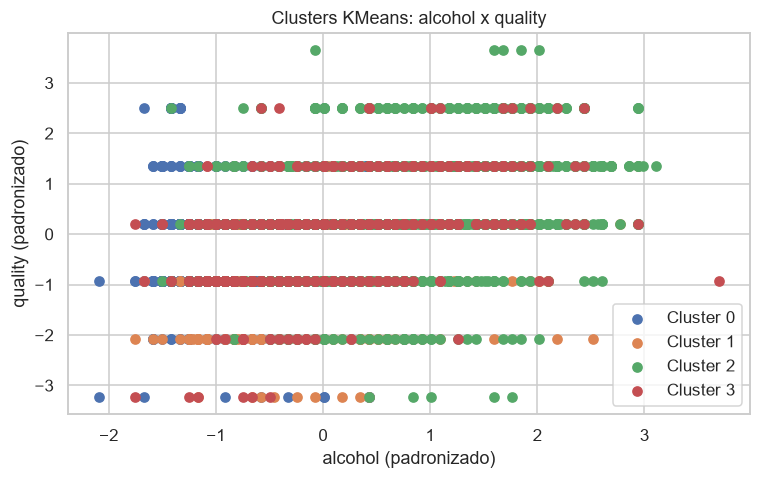

In [20]:
for combination in graph_combinations:
    
    for label in np.unique(km_4.labels_):
        X_ = X[km_4.labels_ == label]
        plt.scatter(
            X_[combination[0]],
            X_[combination[1]],
            label=f"Cluster {label}"
        )
    plt.xlabel(combination[0] + " (padronizado)")
    plt.ylabel(combination[1] + " (padronizado)")
    plt.title("Clusters KMeans: " + combination[0] + " x " + combination[1])
    plt.legend()
    plt.show()

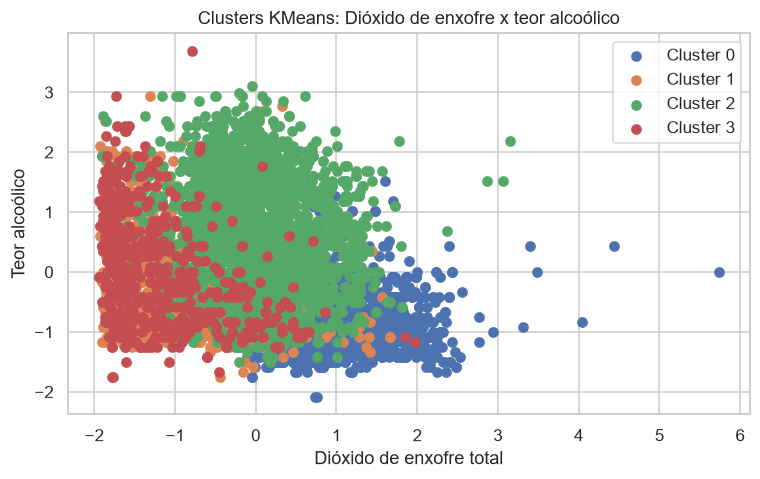

In [21]:
for label in np.unique(km_4.labels_):
    X_ = X[km_4.labels_ == label]
    plt.scatter(
        X_["total_sulfur_dioxide"],
        X_["alcohol"],
        label=f"Cluster {label}"
    )

plt.xlabel("Dióxido de enxofre total")
plt.ylabel("Teor alcoólico")
plt.title("Clusters KMeans: Dióxido de enxofre x teor alcoólico")
plt.legend()
salvar(fig, "4_Clusters_KMeans_Dioxido_Enxofre_x_Teor_Alcoolico")
plt.show()


Através da análise de todos os gráficos o k=2 realmente é o melhor valor de k. Com k=4 os items nos cluster 1 e 3 tem comportamentos muito semelhantes. Enquanto o K=3 apresenta um sillouette score abaixo das outras duas alternativas.

Então k=2 é o escolhido!

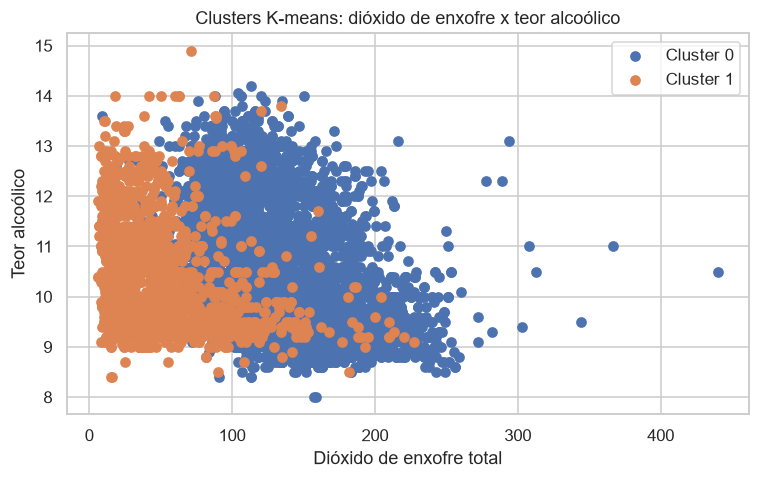

In [22]:
vinhos_clusterizados = vinhos_dataframe[
    ["total_sulfur_dioxide", "alcohol"]
].copy()

vinhos_clusterizados["cluster"] = km_2.labels_

for label in np.unique(vinhos_clusterizados["cluster"]):
    grupo = vinhos_clusterizados[
        vinhos_clusterizados["cluster"] == label
    ]

    plt.scatter(
        grupo["total_sulfur_dioxide"],
        grupo["alcohol"],
        label=f"Cluster {label}"
    )

plt.xlabel("Dióxido de enxofre total")
plt.ylabel("Teor alcoólico")
plt.title("Clusters K-means: dióxido de enxofre x teor alcoólico")
plt.legend()
salvar(fig, "2_Clusters_KMeans_Dioxido_Enxofre_x_Teor_Alcoolico")
plt.show()


Dúvida extra: Será que os dois clusters tem alguma correlação invisível com a cor do vinho?

In [23]:
vinhos_clusterizados = pd.concat(
    [
        vinhos_dataframe[["color", "total_sulfur_dioxide", "alcohol"]],
        pd.Series(km_2.labels_, name="cluster")
    ],
    axis=1
)

# Quantidade de vinhos por cor em cada cluster
contagem_cor_cluster = (
    vinhos_clusterizados.groupby(["cluster", "color"])
    .size()
    .unstack(fill_value=0)
)
print("Cor do vinho por cluster:")
print(contagem_cor_cluster)

print("--------------------------------------------------")

percentual_cor_cluster = (
    contagem_cor_cluster.div(contagem_cor_cluster.sum(axis=1), axis=0) * 100
)
print("Cor do vinho por cluster(percentual):")
print(percentual_cor_cluster)

Cor do vinho por cluster:
color     red  white
cluster             
0          24   4804
1        1575     94
--------------------------------------------------
Cor do vinho por cluster(percentual):
color          red      white
cluster                      
0         0.497100  99.502900
1        94.367885   5.632115


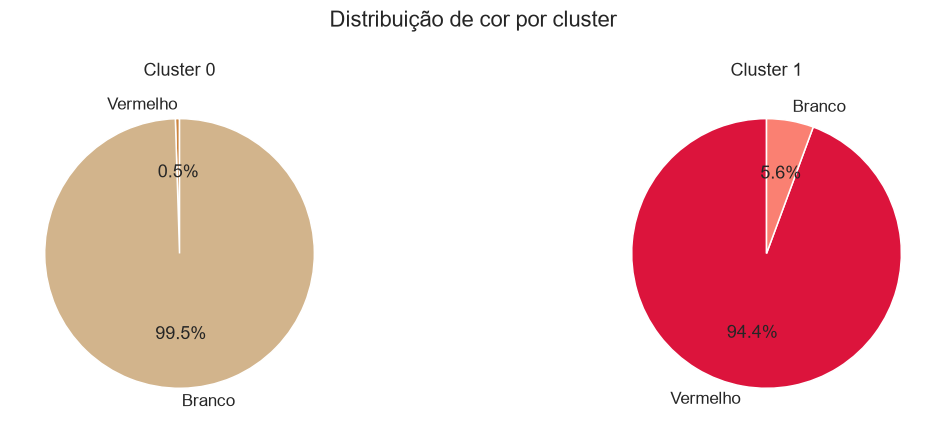

In [24]:
num_branco_0 = vinhos_clusterizados[(vinhos_clusterizados['color'] == 'white') & (vinhos_clusterizados['cluster'] == 0)].shape[0]
num_branco_1 = vinhos_clusterizados[(vinhos_clusterizados['color'] == 'white') & (vinhos_clusterizados['cluster'] == 1)].shape[0]

num_vermelho_0 = vinhos_clusterizados[(vinhos_clusterizados['color'] == 'red') & (vinhos_clusterizados['cluster'] == 0)].shape[0]
num_vermelho_1 = vinhos_clusterizados[(vinhos_clusterizados['color'] == 'red') & (vinhos_clusterizados['cluster'] == 1)].shape[0]

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

labels_cluster_0 = ["Vermelho", "Branco"]
sizes_cluster_0 = [num_vermelho_0, num_branco_0]
colors_cluster_0 = ["peru", "tan"]

labels_cluster_1 = ["Vermelho", "Branco"]
sizes_cluster_1 = [num_vermelho_1, num_branco_1]
colors_cluster_1 = ["crimson", "salmon"]

ax[0].pie(
    sizes_cluster_0,
    labels=labels_cluster_0,
    autopct="%1.1f%%",
    startangle=90,
    colors=colors_cluster_0
)
ax[0].set_title("Cluster 0")

ax[1].pie(
    sizes_cluster_1,
    labels=labels_cluster_1,
    autopct="%1.1f%%",
    startangle=90,
    colors=colors_cluster_1
)
ax[1].set_title("Cluster 1")

plt.suptitle("Distribuição de cor por cluster")
plt.tight_layout()
salvar(fig, "Distribuicao_de_cor_por_cluster_KMeans2")
plt.show()



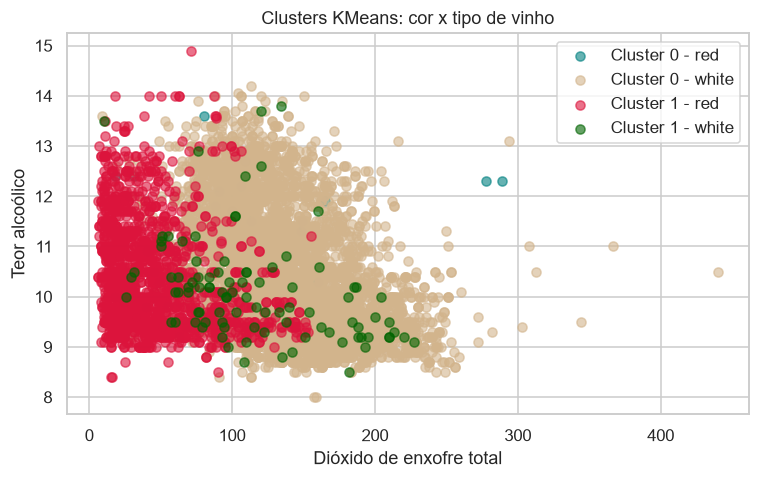

In [25]:
palette = {
    (0, "white"): "tan",
    (0, "red"): "teal",
    (1, "red"): "crimson",
    (1, "white"): "darkgreen",
}

for label in np.unique(km_2.labels_):
    cluster_df = vinhos_clusterizados[vinhos_clusterizados["cluster"] == label]

    for cor in ["red", "white"]:
        subset = cluster_df[cluster_df["color"] == cor]
        color = palette.get((label, cor), "gray")

        plt.scatter(
            subset["total_sulfur_dioxide"],
            subset["alcohol"],
            color=color,
            alpha=0.6,
            label=f"Cluster {label} - {cor}"
        )

plt.xlabel("Dióxido de enxofre total")
plt.ylabel("Teor alcoólico")
plt.title("Clusters KMeans: cor x tipo de vinho")
plt.legend()
salvar(fig, "Distribuicao_de_cor_por_cluster_KMeans2_cores_diferenciadas")
plt.show()


Com isso, podemos dizer que o K-means formou grupos que correspondem principalmente às cores dos vinhos, usando apenas a composição química e a qualidade, sem ter a cor deles na base. No grupo predominantemente branco, cerca de 0,5% dos vinhos eram tintos; no grupo predominantemente tinto, cerca de 5,6% eram brancos.

## Questão 3 - HAC

* Ajuste um modelo de agrupamento aglomerativo com 2 clusters.

* Visualize o dendrograma produzido pelo agrupamento aglomerativo. *Dica:* O SciPy possui um módulo chamado [`cluster.hierarchy`](https://docs.scipy.org/doc/scipy/reference/cluster.hierarchy.html?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMML0187ENSkillsNetwork31430127-2022-01-01#module-scipy.cluster.hierarchy) que contém as funções `linkage` e `dendrogram` necessárias para criar o mapa de ligação e plotar o dendrograma resultante.
* Variando os valores de linkage e o número de clusters, você consegue obter resultados melhores?
* Existe um número melhor para o número de cluster?


In [26]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage

#vou reiniciar o dataframe para o clustering hierárquico, usando o mesmo dataframe de vinhos

vinhos_dataframe = pd.read_csv("https://raw.githubusercontent.com/tonyvieira/aulas_clusterizacao/refs/heads/main/vinhos_dataset.csv")

features = ["fixed_acidity", "volatile_acidity", "citric_acid", "residual_sugar", "chlorides", "free_sulfur_dioxide", "total_sulfur_dioxide", "density", "pH", "sulphates", "alcohol", "quality"]
#já tirando a coluna de cor, pois não é uma feature numérica e não será usada no clustering hierárquico


vinho_hac = vinhos_dataframe[features].copy() 
vinho_hac.head()



,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


Fazer a padronização

In [27]:
scaler = StandardScaler()
vinho_hac_scaled = scaler.fit_transform(vinho_hac)
vinho_hac_scaled[:5]

array([[ 0.14247327,  2.18883292, -2.19283252, -0.7447781 ,  0.56995782,
        -1.10013986, -1.44635852,  1.03499282,  1.81308951,  0.19309677,
        -0.91546416, -0.93722961],
       [ 0.45103572,  3.28223494, -2.19283252, -0.59764007,  1.1979747 ,
        -0.31132009, -0.86246863,  0.70148631, -0.11507303,  0.99957862,
        -0.58006813, -0.93722961],
       [ 0.45103572,  2.55330026, -1.91755268, -0.66069923,  1.02669737,
        -0.87476278, -1.09248586,  0.76818761,  0.25811972,  0.79795816,
        -0.58006813, -0.93722961],
       [ 3.07381662, -0.36243847,  1.66108525, -0.7447781 ,  0.54141159,
        -0.76207424, -0.98632406,  1.10169412, -0.3638682 ,  0.32751041,
        -0.58006813,  0.20799905],
       [ 0.14247327,  2.18883292, -2.19283252, -0.7447781 ,  0.56995782,
        -1.10013986, -1.44635852,  1.03499282,  1.81308951,  0.19309677,
        -0.91546416, -0.93722961]])

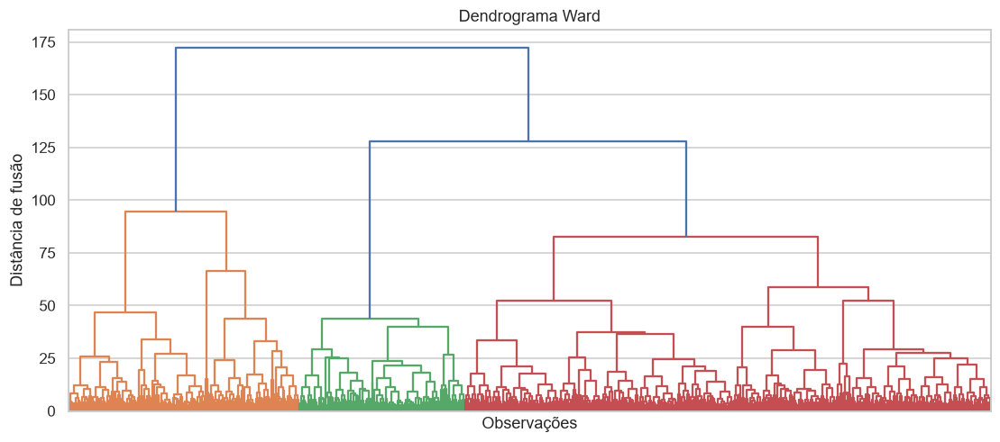

In [28]:
fig = plt.figure(figsize=(12, 5))
Z = linkage(vinho_hac_scaled, method='ward' )

dendrogram(Z, no_labels=True, color_threshold=None)
plt.title('Dendrograma Ward')
plt.xlabel('Observações')
plt.ylabel('Distância de fusão')
salvar(fig, "Dendrograma_Ward")
plt.show()


Aparentemente tem 3 clusters utilizando o methodo ward. Vamos usar o 2 inicial e depois tentar com 3 grupos.

In [29]:
hac = AgglomerativeClustering(n_clusters=2, linkage='ward')
labels_hac = hac.fit_predict(vinho_hac_scaled)
labels_hac[:20]

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 0, 1, 1, 0, 1])

In [30]:
vinho_hac['cluster'] = labels_hac
vinho_hac.head()

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,cluster
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,1
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,1
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1


In [31]:
vinho_hac['cluster'].value_counts().sort_index()


cluster
0    4873
1    1624
Name: count, dtype: int64

In [32]:
clusters_validos = sorted(vinho_hac['cluster'].unique())
n_clusters_encontrados = len(clusters_validos)

print('Número de clusters configurado:', 2)
print('Número de clusters encontrados nos rótulos:', n_clusters_encontrados)

Número de clusters configurado: 2
Número de clusters encontrados nos rótulos: 2


In [33]:
labels_todos = vinho_hac['cluster']

if len(set(labels_todos)) >= 2:
    sil = silhouette_score(vinho_hac_scaled, labels_todos)
    print('Silhouette Score:', round(sil, 4))
else:
    print('Silhouette Score não pode ser calculado: menos de 2 clusters válidos.')

Silhouette Score: 0.2472


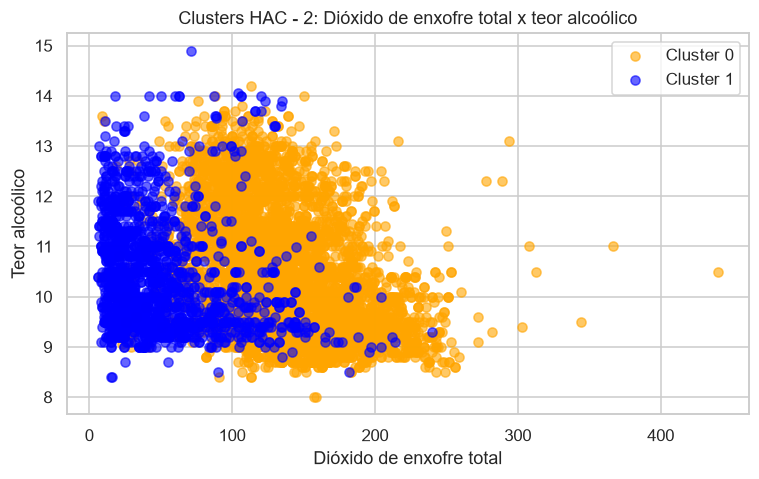

In [34]:
fig = plt.figure()
palette = {
    (0): "orange",
    (1): "blue"
}

for label in np.unique(labels_todos):
    cluster_df = vinho_hac[vinho_hac["cluster"] == label]

    plt.scatter(
            cluster_df["total_sulfur_dioxide"],
            cluster_df["alcohol"],
            color=palette.get(label, "gray"),
            alpha=0.6,
            label=f"Cluster {label}"
        )

plt.xlabel("Dióxido de enxofre total")
plt.ylabel("Teor alcoólico")
plt.title("Clusters HAC - 2: Dióxido de enxofre total x teor alcoólico")
plt.legend()
salvar(fig, "Clusters_HAC_2_Dioxido_Enxofre_x_Teor_Alcoolico")
plt.show()


Bem parecido com o resultado do K-Means com k=2!

Vamos tentar agora com 3 clusters

In [35]:
hac_3 = AgglomerativeClustering(n_clusters=3, linkage='ward')
labels_hac_3 = hac_3.fit_predict(vinho_hac_scaled)
labels_hac_3[:20]

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0])

In [36]:
vinho_hac_3 = vinho_hac.copy()
vinho_hac_3['cluster'] = labels_hac_3
vinho_hac_3.head()

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,cluster
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,0
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0


In [37]:
vinho_hac_3['cluster'].value_counts().sort_index()

cluster
0    1624
1    3701
2    1172
Name: count, dtype: int64

In [38]:
clusters_validos = sorted(vinho_hac_3['cluster'].unique())
n_clusters_encontrados = len(clusters_validos)

print('Número de clusters configurado:', 3)
print('Número de clusters encontrados nos rótulos:', n_clusters_encontrados)

Número de clusters configurado: 3
Número de clusters encontrados nos rótulos: 3


In [39]:
labels_hac_3 = vinho_hac_3['cluster']

if len(set(labels_hac_3)) >= 2:
    sil = silhouette_score(vinho_hac_scaled, labels_hac_3)
    print('Silhouette Score:', round(sil, 4))
else:
    print('Silhouette Score não pode ser calculado: menos de 2 clusters válidos.')

Silhouette Score: 0.1862


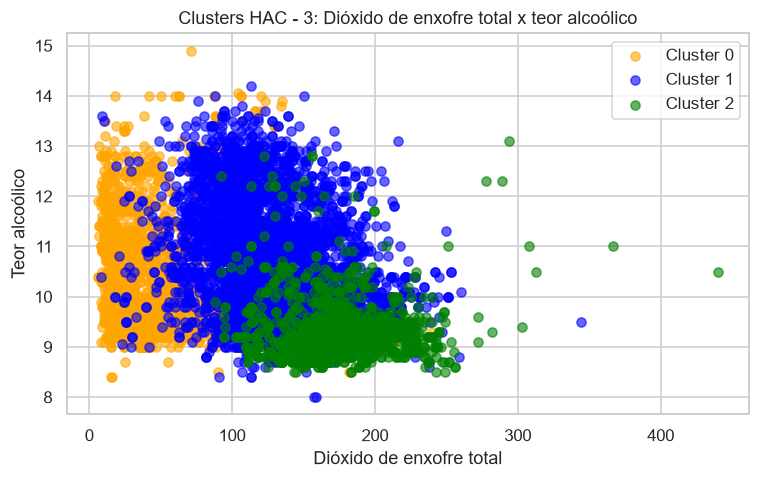

In [40]:
fig = plt.figure()
palette = {
    (0): "orange",
    (1): "blue",
    (2): "green"
}

for label in np.unique(labels_hac_3):
    cluster_df = vinho_hac_3[vinho_hac_3["cluster"] == label]

    plt.scatter(
            cluster_df["total_sulfur_dioxide"],
            cluster_df["alcohol"],
            color=palette.get(label, "gray"),
            alpha=0.6,
            label=f"Cluster {label}"
        )

plt.xlabel("Dióxido de enxofre total")
plt.ylabel("Teor alcoólico")
plt.title("Clusters HAC - 3: Dióxido de enxofre total x teor alcoólico")
plt.legend()
salvar(fig, "Clusters_HAC_3_Dioxido_Enxofre_x_Teor_Alcoolico")
plt.show()


A Silhouette score diminuiu com 3 clusters, um sinal de que 2 clusters seria o melhor. Como não podemos fazer com 1 vamos tentar novamente, mas dessa vez com 4 clusters

In [41]:
hac_4 = AgglomerativeClustering(n_clusters=4, linkage='ward')
labels_hac_4 = hac_4.fit_predict(vinho_hac_scaled)
labels_hac_4[:20]

array([3, 3, 3, 1, 3, 3, 3, 3, 3, 3, 3, 3, 0, 1, 0, 0, 1, 1, 0, 1])

In [42]:
vinho_hac_4 = vinho_hac.copy()
vinho_hac_4['cluster'] = labels_hac_4
vinho_hac_4.head()

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,cluster
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,3
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,3
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,3
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,1
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,3


In [43]:
vinho_hac_4['cluster'].value_counts().sort_index()

cluster
0    3701
1     656
2    1172
3     968
Name: count, dtype: int64

In [44]:
clusters_validos = sorted(vinho_hac_4['cluster'].unique())
n_clusters_encontrados = len(clusters_validos)

print('Número de clusters configurado:', 4)
print('Número de clusters encontrados nos rótulos:', n_clusters_encontrados)

Número de clusters configurado: 4
Número de clusters encontrados nos rótulos: 4


In [45]:
labels_hac_4 = vinho_hac_4['cluster']

if len(set(labels_hac_4)) >= 2:
    sil = silhouette_score(vinho_hac_scaled, labels_hac_4)
    print('Silhouette Score:', round(sil, 4))
else:
    print('Silhouette Score não pode ser calculado: menos de 2 clusters válidos.')

Silhouette Score: 0.1899


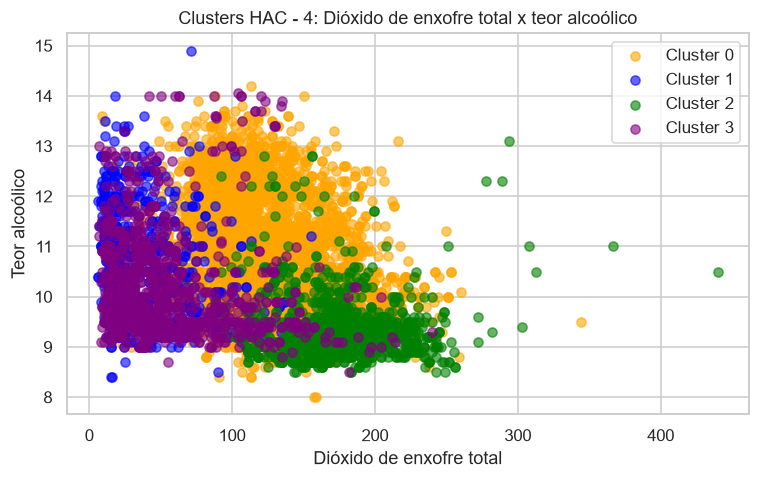

In [46]:
fig = plt.figure()
palette = {
    (0): "orange",
    (1): "blue",
    (2): "green",
    (3): "purple"
}

for label in np.unique(labels_hac_4):
    cluster_df = vinho_hac_4[vinho_hac_4["cluster"] == label]

    plt.scatter(
            cluster_df["total_sulfur_dioxide"],
            cluster_df["alcohol"],
            color=palette.get(label, "gray"),
            alpha=0.6,
            label=f"Cluster {label}"
        )

plt.xlabel("Dióxido de enxofre total")
plt.ylabel("Teor alcoólico")
plt.title("Clusters HAC - 4: Dióxido de enxofre total x teor alcoólico")
plt.legend()
salvar(fig, "Clusters_HAC_4_Dioxido_Enxofre_x_Teor_Alcoolico")
plt.show()


Como 2 clusters temos um silhouette score melhor selecionamos ele. Vamos então tentar mudar os métodos de linkage.

Segundo tentaremos o complete

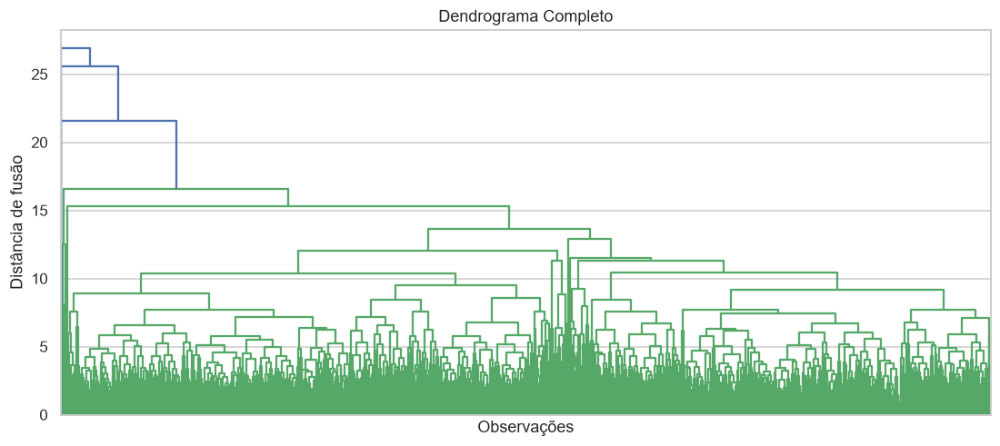

In [47]:
fig = plt.figure(figsize=(12, 5))
Z = linkage(vinho_hac_scaled, method='complete' )

dendrogram(Z, no_labels=True, color_threshold=None)
plt.title('Dendrograma Completo')
plt.xlabel('Observações')
plt.ylabel('Distância de fusão')
salvar(fig, "Dendrograma_Complete")
plt.show()


In [48]:
vinho_hac_2_complete = vinhos_dataframe[features].copy() 

hac_2_complete = AgglomerativeClustering(n_clusters=2, linkage='complete')
labels_hac_2_complete = hac_2_complete.fit_predict(vinho_hac_scaled)
labels_hac_2_complete[:20]

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

In [49]:
vinho_hac_2_complete['cluster'] = labels_hac_2_complete

vinho_hac_2_complete['cluster'].value_counts().sort_index()

cluster
0    6496
1       1
Name: count, dtype: int64

Resultado muito esquisito! Vamos dar uma olhada no gráfico para ver o que ele marcou

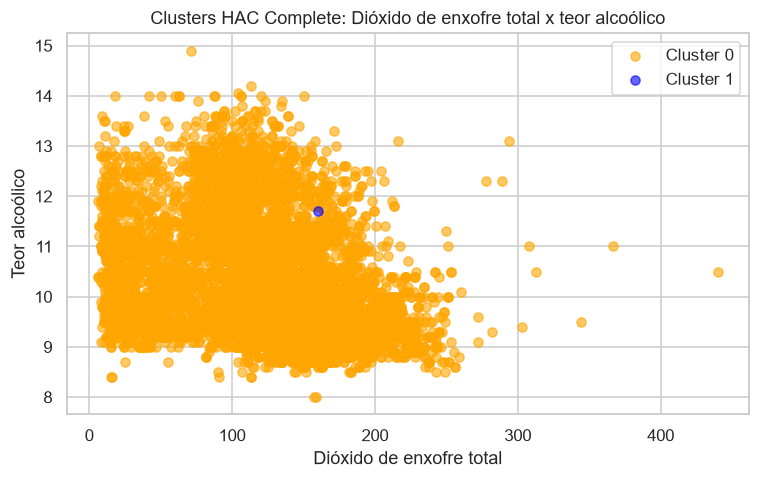

In [50]:
palette = {
    (0): "orange",
    (1): "blue"
}

for label in np.unique(labels_hac_2_complete):
    cluster_df = vinho_hac_2_complete[vinho_hac_2_complete["cluster"] == label]

    plt.scatter(
            cluster_df["total_sulfur_dioxide"],
            cluster_df["alcohol"],
            color=palette.get(label, "gray"),
            alpha=0.6,
            label=f"Cluster {label}"
        )

plt.xlabel("Dióxido de enxofre total")
plt.ylabel("Teor alcoólico")
plt.title("Clusters HAC Complete: Dióxido de enxofre total x teor alcoólico")
plt.legend()
plt.show()

In [51]:
esquisito = vinho_hac_2_complete[vinho_hac_2_complete['cluster'] == 1]
esquisito.head()

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,cluster
4380,7.8,0.965,0.6,65.8,0.074,8.0,160.0,1.03898,3.39,0.69,11.7,6,1


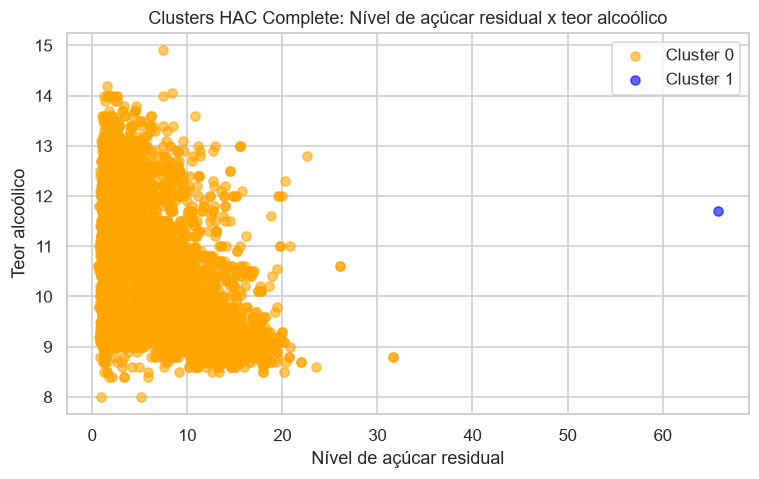

In [52]:
fig = plt.figure()
palette = {
    (0): "orange",
    (1): "blue"
}

for label in np.unique(labels_hac_2_complete):
    cluster_df = vinho_hac_2_complete[vinho_hac_2_complete["cluster"] == label]

    plt.scatter(
            cluster_df["residual_sugar"],
            cluster_df["alcohol"],
            color=palette.get(label, "gray"),
            alpha=0.6,
            label=f"Cluster {label}"
        )

plt.xlabel("Nível de açúcar residual")
plt.ylabel("Teor alcoólico")
plt.title("Clusters HAC Complete: Nível de açúcar residual x teor alcoólico")
plt.legend()
salvar(fig, "Clusters_HAC_Complete_Residual_Sugar_x_Teor_Alcoolico")
plt.show()


O método complete separou um vinho com teor de açúcar residual muito alto dos demais. Para este conjunto de dados, essa divisão não pareceu muito útil.

Vamos tentar com o average então

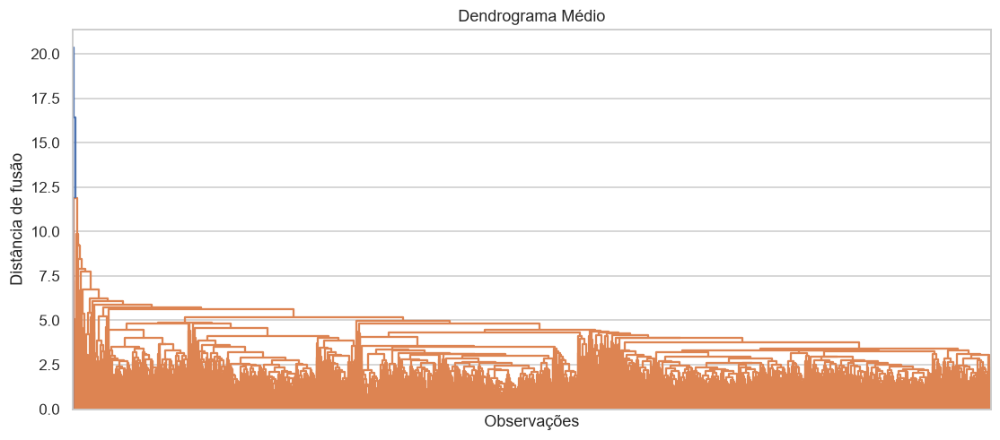

In [53]:
fig = plt.figure(figsize=(12, 5))
Z = linkage(vinho_hac_scaled, method='average' )

dendrogram(Z, no_labels=True, color_threshold=None)
plt.title('Dendrograma Médio')
plt.xlabel('Observações')
plt.ylabel('Distância de fusão')
salvar(fig, "Dendrograma_Average")
plt.show()


In [54]:
vinho_hac_2_average = vinhos_dataframe[features].copy() 

hac_2_average = AgglomerativeClustering(n_clusters=2, linkage='average')
labels_hac_2_average = hac_2_average.fit_predict(vinho_hac_scaled)
labels_hac_2_average[:20]

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

In [55]:
vinho_hac_2_average['cluster'] = labels_hac_2_average

vinho_hac_2_average['cluster'].value_counts().sort_index()

cluster
0    6496
1       1
Name: count, dtype: int64

Tenho a impressão que ele fez a mesma coisa

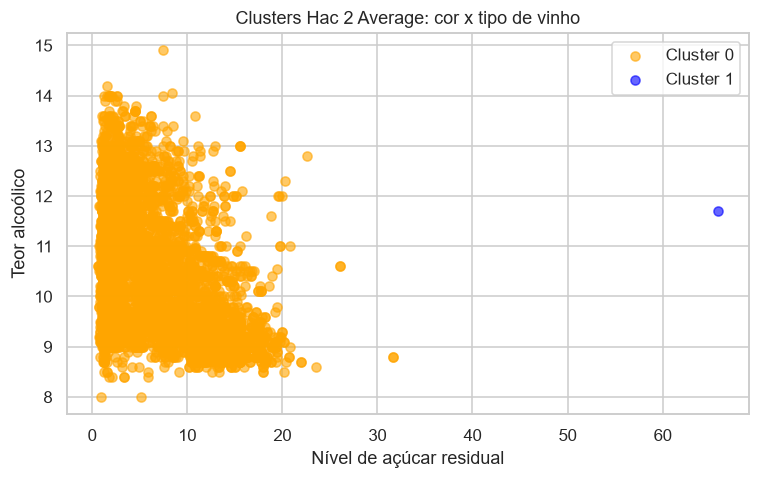

In [56]:
fig = plt.figure()
palette = {
    (0): "orange",
    (1): "blue"
}

for label in np.unique(labels_hac_2_average):
    cluster_df = vinho_hac_2_average[vinho_hac_2_average["cluster"] == label]

    plt.scatter(
            cluster_df["residual_sugar"],
            cluster_df["alcohol"],
            color=palette.get(label, "gray"),
            alpha=0.6,
            label=f"Cluster {label}"
        )

plt.xlabel("Nível de açúcar residual")
plt.ylabel("Teor alcoólico")
plt.title("Clusters Hac 2 Average: cor x tipo de vinho")
plt.legend()
salvar(fig, "Clusters_HAC_Average_Residual_Sugar_x_Teor_Alcoolico")
plt.show()


Pelos resultados deste teste, o método Ward pareceu funcionar melhor para esses dados. Já os métodos complete e average formaram grupos menos úteis, possivelmente por serem mais sensíveis aos valores extremos.

Vamos ver como o HAC está em comparação com o kmeans!

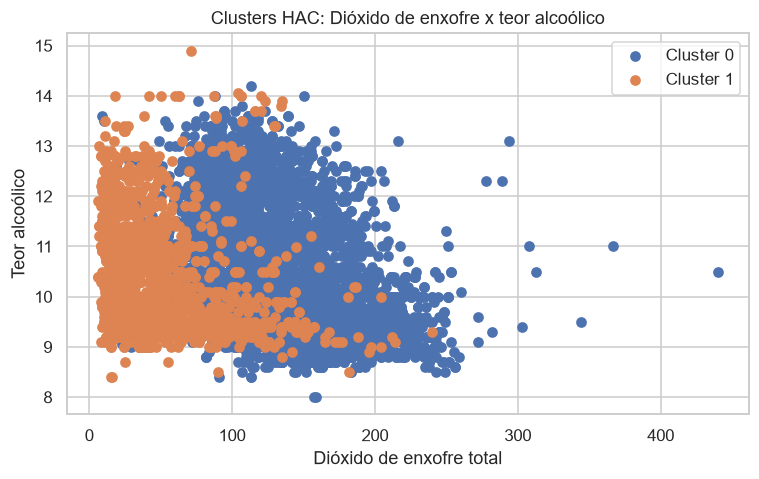

In [57]:
fig = plt.figure()
vinho_hac = pd.concat(
    [
        vinhos_dataframe,
        pd.Series(labels_todos, name="cluster")
    ],
    axis=1
)

for label in np.unique(labels_todos):
    X_ = vinho_hac[vinho_hac["cluster"] == label]
    plt.scatter(
        X_["total_sulfur_dioxide"],
        X_["alcohol"],
        label=f"Cluster {label}"
    )

plt.xlabel("Dióxido de enxofre total")
plt.ylabel("Teor alcoólico")
plt.title("Clusters HAC: Dióxido de enxofre x teor alcoólico")
plt.legend()
salvar(fig, "2_Clusters_HAC_Dioxido_Enxofre_x_Teor_Alcoolico")
plt.show()


In [58]:
vinho_hac = vinhos_dataframe.copy()
vinho_hac["cluster"] = labels_todos

contagem_cor_cluster = (
    vinho_hac.groupby(["cluster", "color"])
    .size()
    .unstack(fill_value=0)
)

print("Quantidade de vinhos por cor em cada cluster:")
print(contagem_cor_cluster)

percentual_cor_cluster = (
    contagem_cor_cluster
    .div(contagem_cor_cluster.sum(axis=1), axis=0)
    * 100
)

print("\nPercentual de cada cor dentro dos clusters:")
print(percentual_cor_cluster)

Quantidade de vinhos por cor em cada cluster:
color     red  white
cluster             
0          43   4830
1        1556     68

Percentual de cada cor dentro dos clusters:
color          red      white
cluster                      
0         0.882413  99.117587
1        95.812808   4.187192


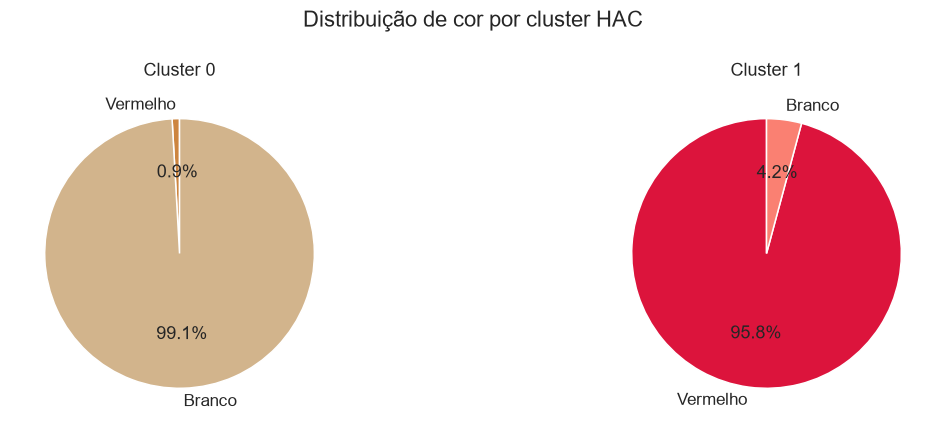

In [59]:
num_branco_0 = vinho_hac[(vinho_hac['color'] == 'white') & (vinho_hac['cluster'] == 0)].shape[0]
num_branco_1 = vinho_hac[(vinho_hac['color'] == 'white') & (vinho_hac['cluster'] == 1)].shape[0]

num_vermelho_0 = vinho_hac[(vinho_hac['color'] == 'red') & (vinho_hac['cluster'] == 0)].shape[0]
num_vermelho_1 = vinho_hac[(vinho_hac['color'] == 'red') & (vinho_hac['cluster'] == 1)].shape[0]

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

labels_cluster_0 = ["Vermelho", "Branco"]
sizes_cluster_0 = [num_vermelho_0, num_branco_0]
colors_cluster_0 = ["peru", "tan"]

labels_cluster_1 = ["Vermelho", "Branco"]
sizes_cluster_1 = [num_vermelho_1, num_branco_1]
colors_cluster_1 = ["crimson", "salmon"]

ax[0].pie(
    sizes_cluster_0,
    labels=labels_cluster_0,
    autopct="%1.1f%%",
    startangle=90,
    colors=colors_cluster_0
)
ax[0].set_title("Cluster 0")

ax[1].pie(
    sizes_cluster_1,
    labels=labels_cluster_1,
    autopct="%1.1f%%",
    startangle=90,
    colors=colors_cluster_1
)
ax[1].set_title("Cluster 1")

plt.suptitle("Distribuição de cor por cluster HAC")
plt.tight_layout()
salvar(fig, "Distribuicao_de_cor_por_cluster_HAC")
plt.show()


Em comparação com o K-means, o HAC separou um pouco melhor os vinhos tintos: a proporção de vinhos brancos no grupo predominantemente tinto caiu de 5,6% para 4,2%. Por outro lado, no grupo predominantemente branco, a proporção de tintos subiu de 0,5% para 0,9%. Então, os resultados foram parecidos, com uma pequena melhora na separação dos tintos e uma pequena piora na dos brancos.

## Questão 4 - DBSCAN

* Crie um modelo de com o algoritmo DBSCAN com:

- `eps=3`

- `min_samples=4`

* Quandos clusters foram gerados?
* Visualize os resultados dos clusters gerados.
* Variando os valores de eps e min_samples, você consegue obter resultados melhores?

In [60]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors

#vou reiniciar o dataframe para o dbscan, usando o mesmo dataframe de vinhos

vinhos_dataframe = pd.read_csv("https://raw.githubusercontent.com/tonyvieira/aulas_clusterizacao/refs/heads/main/vinhos_dataset.csv")

features = ["fixed_acidity", "volatile_acidity", "citric_acid", "residual_sugar", "chlorides", "free_sulfur_dioxide", "total_sulfur_dioxide", "density", "pH", "sulphates", "alcohol", "quality"]
#já tirando a coluna de cor, pois não é uma feature numérica e não será usada no clustering hierárquico


vinho_dbscan = vinhos_dataframe[features].copy() 
vinho_dbscan.head()

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [61]:
scaler = StandardScaler()
vinho_dbscan_scaled = scaler.fit_transform(vinho_dbscan)
vinho_dbscan_scaled[:5]

array([[ 0.14247327,  2.18883292, -2.19283252, -0.7447781 ,  0.56995782,
        -1.10013986, -1.44635852,  1.03499282,  1.81308951,  0.19309677,
        -0.91546416, -0.93722961],
       [ 0.45103572,  3.28223494, -2.19283252, -0.59764007,  1.1979747 ,
        -0.31132009, -0.86246863,  0.70148631, -0.11507303,  0.99957862,
        -0.58006813, -0.93722961],
       [ 0.45103572,  2.55330026, -1.91755268, -0.66069923,  1.02669737,
        -0.87476278, -1.09248586,  0.76818761,  0.25811972,  0.79795816,
        -0.58006813, -0.93722961],
       [ 3.07381662, -0.36243847,  1.66108525, -0.7447781 ,  0.54141159,
        -0.76207424, -0.98632406,  1.10169412, -0.3638682 ,  0.32751041,
        -0.58006813,  0.20799905],
       [ 0.14247327,  2.18883292, -2.19283252, -0.7447781 ,  0.56995782,
        -1.10013986, -1.44635852,  1.03499282,  1.81308951,  0.19309677,
        -0.91546416, -0.93722961]])

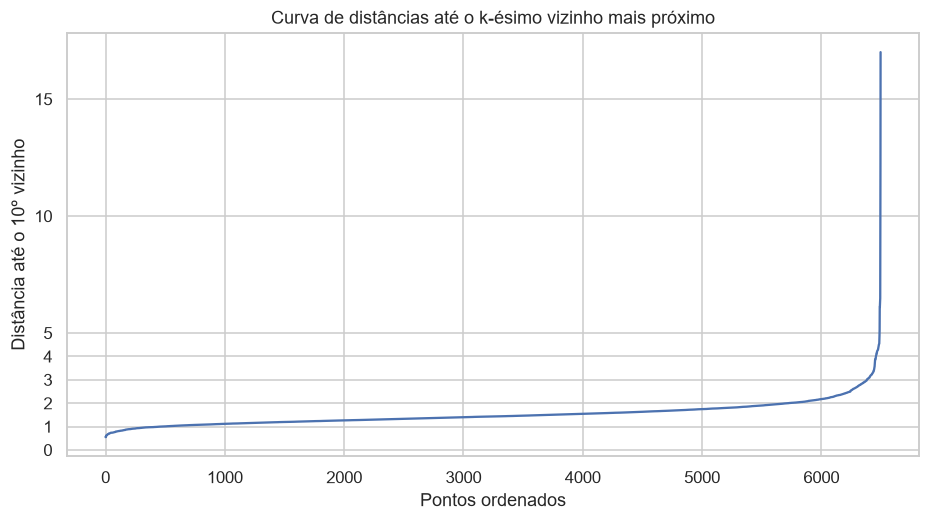

In [62]:
min_samples = 10

neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors_fit = neighbors.fit(vinho_dbscan_scaled)
distances, indices = neighbors_fit.kneighbors(vinho_dbscan_scaled)

distancias_k = np.sort(distances[:, min_samples - 1])

fig, ax = plt.subplots(1, figsize=(10, 5))

plt.plot(distancias_k)
plt.title('Curva de distâncias até o k-ésimo vizinho mais próximo')
plt.xlabel('Pontos ordenados')
ax.set_yticks([0, 1, 2, 3, 4, 5, 10, 15])
plt.ylabel(f'Distância até o {min_samples}º vizinho')
salvar(fig, "Curva_Distancias_k_esimo_vizinho_DBSCAN")
plt.show()


Realmente o valor 3 parece um bom valor de ep

In [63]:
dbscan = DBSCAN(eps=3, min_samples=4)
vinho_dbscan_labels= dbscan.fit_predict(vinho_dbscan_scaled)
vinho_dbscan_labels[:20]

array([ 0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0, -1,  0,  0,  0,
        1,  0,  1])

In [64]:
vinho_dbscan['cluster'] = vinho_dbscan_labels
vinho_dbscan.head()

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,cluster
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,0
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0


In [65]:
clusters_validos = sorted([c for c in vinho_dbscan['cluster'].unique() if c != -1])
n_clusters_encontrados = len(clusters_validos)
n_ruidos = (vinho_dbscan['cluster'] == -1).sum()

print('Número de clusters encontrados:', n_clusters_encontrados)
print('Quantidade de pontos marcados como ruído:', n_ruidos)

Número de clusters encontrados: 3
Quantidade de pontos marcados como ruído: 35


In [66]:
vinho_dbscan['cluster'].value_counts().sort_index()

cluster
-1      35
 0    6442
 1      16
 2       4
Name: count, dtype: int64

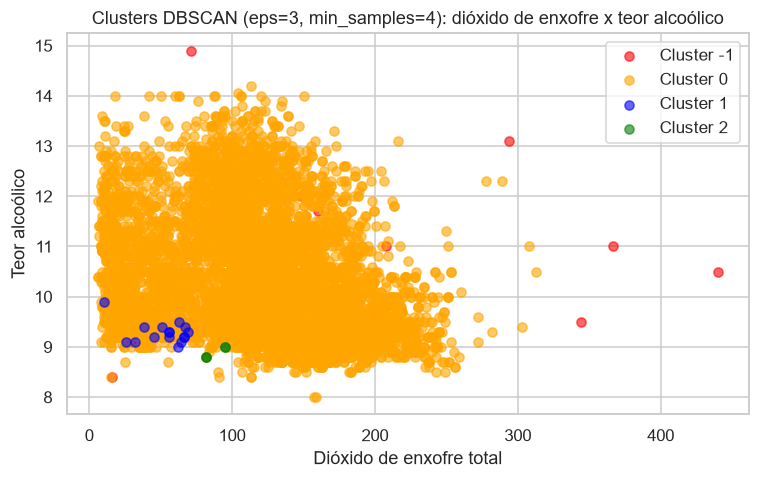

In [67]:
fig = plt.figure()
palette = {
    (-1): "red",
    (0): "orange",
    (1): "blue",
    (2): "green"
}

for label in np.unique(vinho_dbscan_labels):
    cluster_df = vinho_dbscan[vinho_dbscan["cluster"] == label]

    plt.scatter(
            cluster_df["total_sulfur_dioxide"],
            cluster_df["alcohol"],
            color=palette.get(label, "gray"),
            alpha=0.6,
            label=f"Cluster {label}"
        )

plt.xlabel("Dióxido de enxofre total")
plt.ylabel("Teor alcoólico")
plt.title("Clusters DBSCAN (eps=3, min_samples=4): dióxido de enxofre x teor alcoólico")
plt.legend()
salvar(fig, "Clusters_DBSCAN_Dioxido_Enxofre_x_Teor_Alcoolico")
plt.show()


Nesse gráfico não fica muito intuitivo, vamos ver o que ele definiu com os clusters 1 e 2

In [68]:
cluster1 = vinho_dbscan[vinho_dbscan['cluster'] == 1]
cluster1.head()

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,cluster
17,8.1,0.56,0.28,1.7,0.368,16.0,56.0,0.9968,3.11,1.28,9.3,5,1
19,7.9,0.32,0.51,1.8,0.341,17.0,56.0,0.9969,3.04,1.08,9.2,6,1
81,7.8,0.43,0.70,1.9,0.464,22.0,67.0,0.9974,3.13,1.28,9.4,5,1
83,7.3,0.67,0.26,1.8,0.401,16.0,51.0,0.9969,3.16,1.14,9.4,5,1
106,7.8,0.41,0.68,1.7,0.467,18.0,69.0,0.9973,3.08,1.31,9.3,5,1


In [69]:
cluster2 = vinho_dbscan[vinho_dbscan['cluster'] == 2]
cluster2.head()

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,cluster
1434,10.2,0.54,0.37,15.4,0.214,55.0,95.0,1.00369,3.18,0.77,9.0,6,2
1435,10.2,0.54,0.37,15.4,0.214,55.0,95.0,1.00369,3.18,0.77,9.0,6,2
1474,9.9,0.50,0.50,13.8,0.205,48.0,82.0,1.00242,3.16,0.75,8.8,5,2
1476,9.9,0.50,0.50,13.8,0.205,48.0,82.0,1.00242,3.16,0.75,8.8,5,2


Aparentemente é sobre os níveis de açucar novamente

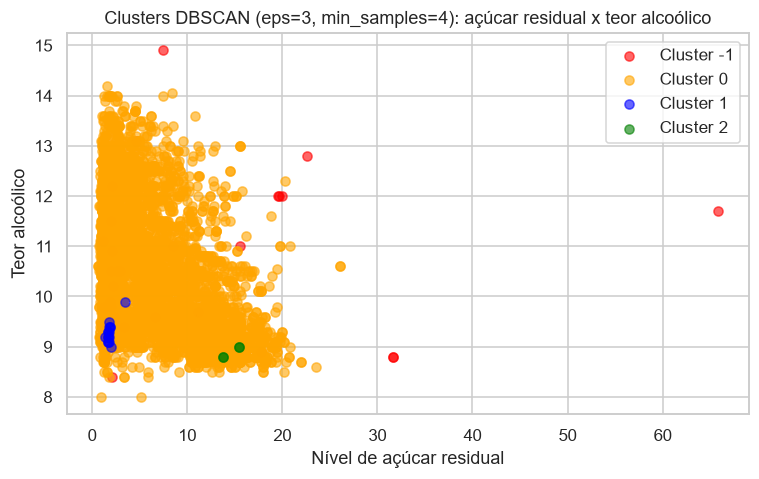

In [70]:
fig = plt.figure()
palette = {
    (-1): "red",
    (0): "orange",
    (1): "blue",
    (2): "green"
}

for label in np.unique(vinho_dbscan_labels):
    cluster_df = vinho_dbscan[vinho_dbscan["cluster"] == label]
    plt.scatter(
            cluster_df["residual_sugar"],
            cluster_df["alcohol"],
            color=palette.get(label, "gray"),
            alpha=0.6,
            label=f"Cluster {label}"
        )

plt.xlabel("Nível de açúcar residual")
plt.ylabel("Teor alcoólico")
plt.title("Clusters DBSCAN (eps=3, min_samples=4): açúcar residual x teor alcoólico")
plt.legend()
salvar(fig, "Clusters_DBSCAN_Residual_Sugar_x_Teor_Alcoolico")
plt.show()


Aparentemente não... era a única coisa que parecia discrepante nos heads dos dois. Vou tentar continuar o exercício e tentar eps=4

In [71]:
dbscan_ep4 = DBSCAN(eps=4, min_samples=4)
vinho_dbscan_labels_ep4= dbscan_ep4.fit_predict(vinho_dbscan_scaled)
vinho_dbscan_labels_ep4[:20]

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

In [72]:
vinho_dbscan_ep4 = vinho_dbscan.copy()
vinho_dbscan_ep4['cluster'] = vinho_dbscan_labels_ep4


clusters_validos = sorted([c for c in vinho_dbscan_ep4['cluster'].unique() if c != -1])
n_clusters_encontrados = len(clusters_validos)
n_ruidos = (vinho_dbscan_ep4['cluster'] == -1).sum()

print('Número de clusters encontrados:', n_clusters_encontrados)
print('Quantidade de pontos marcados como ruído:', n_ruidos)

Número de clusters encontrados: 1
Quantidade de pontos marcados como ruído: 6


In [73]:
vinho_dbscan_ep4['cluster'].value_counts().sort_index()

cluster
-1       6
 0    6491
Name: count, dtype: int64

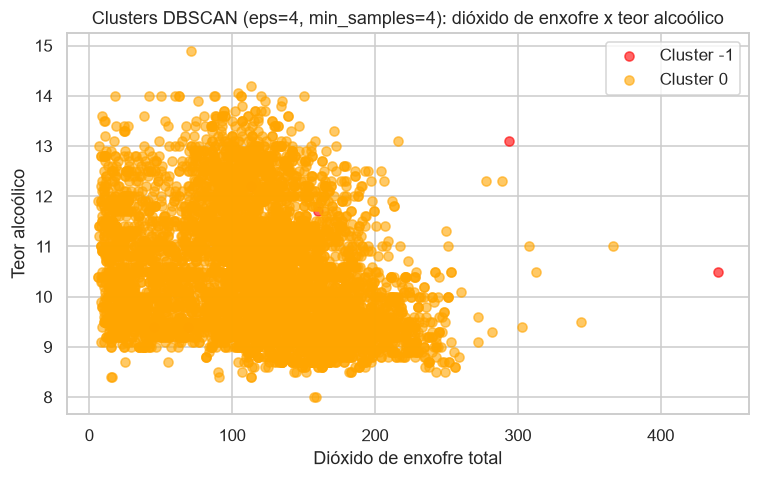

In [74]:
fig = plt.figure()
palette = {
    (-1): "red",
    (0): "orange",
    (1): "blue",
    (2): "green"
}

for label in np.unique(vinho_dbscan_labels_ep4):
    cluster_df = vinho_dbscan_ep4[vinho_dbscan_ep4["cluster"] == label]

    plt.scatter(
            cluster_df["total_sulfur_dioxide"],
            cluster_df["alcohol"],
            color=palette.get(label, "gray"),
            alpha=0.6,
            label=f"Cluster {label}"
        )

plt.xlabel("Dióxido de enxofre total")
plt.ylabel("Teor alcoólico")
plt.title("Clusters DBSCAN (eps=4, min_samples=4): dióxido de enxofre x teor alcoólico")
plt.legend()
salvar(fig, "Clusters_DBSCAN_eps4_Dioxido_Enxofre_x_Teor_Alcoolico")
plt.show()


Aumentando a distancia ele une tudo em um cluster só. Identificando apenas outliers

In [75]:
dbscan_ep2 = DBSCAN(eps=2, min_samples=4)
vinho_dbscan_labels_ep2= dbscan_ep2.fit_predict(vinho_dbscan_scaled)
vinho_dbscan_labels_ep2[:20]

array([ 0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0, -1, -1, -1,  0,
       -1,  0,  2])

In [76]:
vinho_dbscan_ep2 = vinho_dbscan.copy()
vinho_dbscan_ep2['cluster'] = vinho_dbscan_labels_ep2


clusters_validos = sorted([c for c in vinho_dbscan_ep2['cluster'].unique() if c != -1])
n_clusters_encontrados = len(clusters_validos)
n_ruidos = (vinho_dbscan_ep2['cluster'] == -1).sum()

print('Número de clusters encontrados:', n_clusters_encontrados)
print('Quantidade de pontos marcados como ruído:', n_ruidos)

Número de clusters encontrados: 8
Quantidade de pontos marcados como ruído: 214


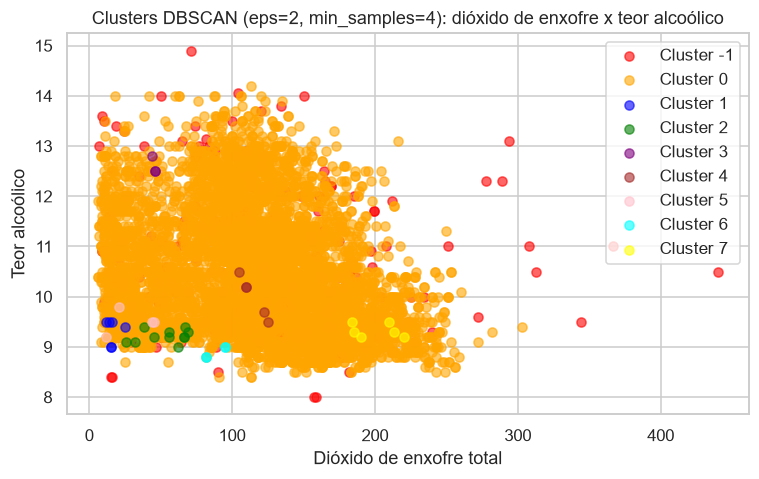

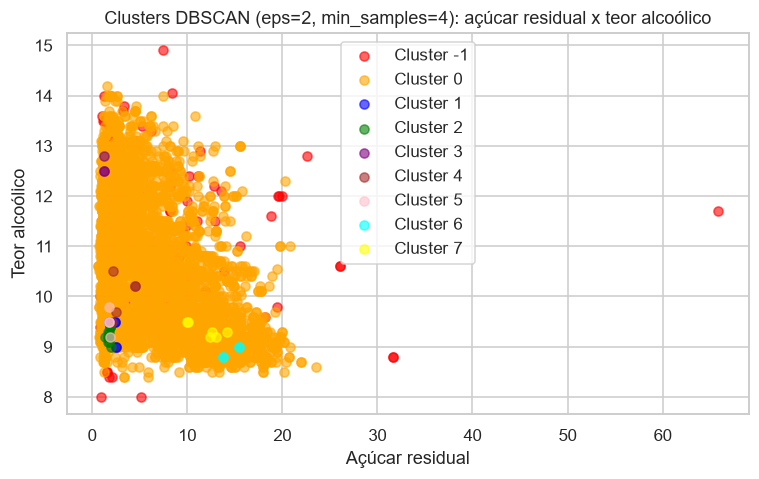

In [77]:
fig = plt.figure()
palette = {
    (-1): "red",
    (0): "orange",
    (1): "blue",
    (2): "green",
    (3): "purple",
    (4): "brown",
    (5): "pink",
    (6): "cyan",
    (7): "yellow",

}

for label in np.unique(vinho_dbscan_labels_ep2):
    cluster_df = vinho_dbscan_ep2[vinho_dbscan_ep2["cluster"] == label]

    plt.scatter(
            cluster_df["total_sulfur_dioxide"],
            cluster_df["alcohol"],
            color=palette.get(label, "gray"),
            alpha=0.6,
            label=f"Cluster {label}"
        )

plt.xlabel("Dióxido de enxofre total")
plt.ylabel("Teor alcoólico")
plt.title("Clusters DBSCAN (eps=2, min_samples=4): dióxido de enxofre x teor alcoólico")
plt.legend()
plt.show()

for label in np.unique(vinho_dbscan_labels_ep2):
    cluster_df = vinho_dbscan_ep2[vinho_dbscan_ep2["cluster"] == label]

    plt.scatter(
            cluster_df["residual_sugar"],
            cluster_df["alcohol"],
            color=palette.get(label, "gray"),
            alpha=0.6,
            label=f"Cluster {label}"
        )

plt.xlabel("Açúcar residual")
plt.ylabel("Teor alcoólico")
plt.title("Clusters DBSCAN (eps=2, min_samples=4): açúcar residual x teor alcoólico")
plt.legend()
salvar(fig, "Clusters_DBSCAN_eps2_Residual_Sugar_x_Teor_Alcoolico")
plt.show()


Diminuindo o tamanho de ep também não parece clusterizar bem. Temos vários clusters mas o cluster 0 continua denso e forte.

## Questão 5 - MeanShift

* Crie um modelo de com o algoritmo MeanShift com:

- bandwidth_estimado

* Quandos clusters foram gerados?
* Visualize os resultados dos clusters gerados.
* Variando os valores de bandwidth, você consegue obter resultados melhores?


In [78]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import MeanShift, estimate_bandwidth
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

#vou reiniciar o dataframe para o dbscan, usando o mesmo dataframe de vinhos

vinhos_dataframe = pd.read_csv("https://raw.githubusercontent.com/tonyvieira/aulas_clusterizacao/refs/heads/main/vinhos_dataset.csv")

features = ["fixed_acidity", "volatile_acidity", "citric_acid", "residual_sugar", "chlorides", "free_sulfur_dioxide", "total_sulfur_dioxide", "density", "pH", "sulphates", "alcohol", "quality"]
#já tirando a coluna de cor, pois não é uma feature numérica e não será usada no clustering hierárquico



vinho_meanshift = vinhos_dataframe[features].copy() 
vinho_meanshift.head()

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [79]:
scaler = StandardScaler()
vinho_meanshift_scaled = scaler.fit_transform(vinho_meanshift)
vinho_meanshift_scaled[:5]

array([[ 0.14247327,  2.18883292, -2.19283252, -0.7447781 ,  0.56995782,
        -1.10013986, -1.44635852,  1.03499282,  1.81308951,  0.19309677,
        -0.91546416, -0.93722961],
       [ 0.45103572,  3.28223494, -2.19283252, -0.59764007,  1.1979747 ,
        -0.31132009, -0.86246863,  0.70148631, -0.11507303,  0.99957862,
        -0.58006813, -0.93722961],
       [ 0.45103572,  2.55330026, -1.91755268, -0.66069923,  1.02669737,
        -0.87476278, -1.09248586,  0.76818761,  0.25811972,  0.79795816,
        -0.58006813, -0.93722961],
       [ 3.07381662, -0.36243847,  1.66108525, -0.7447781 ,  0.54141159,
        -0.76207424, -0.98632406,  1.10169412, -0.3638682 ,  0.32751041,
        -0.58006813,  0.20799905],
       [ 0.14247327,  2.18883292, -2.19283252, -0.7447781 ,  0.56995782,
        -1.10013986, -1.44635852,  1.03499282,  1.81308951,  0.19309677,
        -0.91546416, -0.93722961]])

In [80]:
bandwidth_estimado = estimate_bandwidth(vinho_meanshift_scaled, quantile=0.2)
bandwidth_estimado

np.float64(3.557711629128935)

In [81]:
meanshift = MeanShift(bandwidth=bandwidth_estimado)
meanshift.fit(vinho_meanshift_scaled)

,"bandwidth bandwidth: float, default=NoneBandwidth used in the flat kernel.If not given, the bandwidth is estimated usingsklearn.cluster.estimate_bandwidth; see the documentation for thatfunction for hints on scalability (see also the Notes, below).",np.float64(3.557711629128935)
,"seeds seeds: array-like of shape (n_samples, n_features), default=NoneSeeds used to initialize kernels. If not set,the seeds are calculated by clustering.get_bin_seedswith bandwidth as the grid size and default values forother parameters.",None
,"bin_seeding bin_seeding: bool, default=FalseIf true, initial kernel locations are not locations of allpoints, but rather the location of the discretized version ofpoints, where points are binned onto a grid whose coarsenesscorresponds to the bandwidth. Setting this option to True will speedup the algorithm because fewer seeds will be initialized.The default value is False.Ignored if seeds argument is not None.",False
,"min_bin_freq min_bin_freq: int, default=1To speed up the algorithm, accept only those bins with at leastmin_bin_freq points as seeds.",1
,"cluster_all cluster_all: bool, default=TrueIf true, then all points are clustered, even those orphans that arenot within any kernel. Orphans are assigned to the nearest kernel.If false, then orphans are given cluster label -1.",True
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. The following tasks benefitfrom the parallelization:- The search of nearest neighbors for bandwidth estimation and label assignments. See the details in the docstring of the ``NearestNeighbors`` class.- Hill-climbing optimization for all seeds.See :term:`Glossary <n_jobs>` for more details.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"max_iter max_iter: int, default=300Maximum number of iterations, per seed point before the clusteringoperation terminates (for that seed point), if has not converged yet... versionadded:: 0.22",300
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers.","ndarray[float64](15, 12)","[[-0.25,-0.34, 0. ,...,-0.25, 0.09, 0.07], [ 0.81, 1.31, 1.4 ,..., 4.76,-1.03,-0.58], [ 0.91, 1. , 0.45,..., 2.9 ,-0.74,-0.43], ..., [ 0.14,-0.85, 9.23,..., 0.13, 1.43, 0.21], [-0.32, 2.89,-2.19,...,-0.14,-0.58,-3.23], [-0.86,-0.48,-0.47,..., 0.73, 0.01,-3.23]]"
"labels_ labels_: ndarray of shape (n_samples,)Labels of each point.","ndarray[int64](6497,)","[0,0,0,...,0,0,0]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,12


In [82]:
vinho_meanshift['cluster'] = meanshift.labels_
vinho_meanshift.head()

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,cluster
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,5
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0


In [83]:
vinho_meanshift['cluster'].value_counts().sort_index()

cluster
0     6135
1       16
2       51
3       25
4       10
5      153
6        1
7       25
8        1
9        1
10      10
11      36
12       1
13      31
14       1
Name: count, dtype: int64

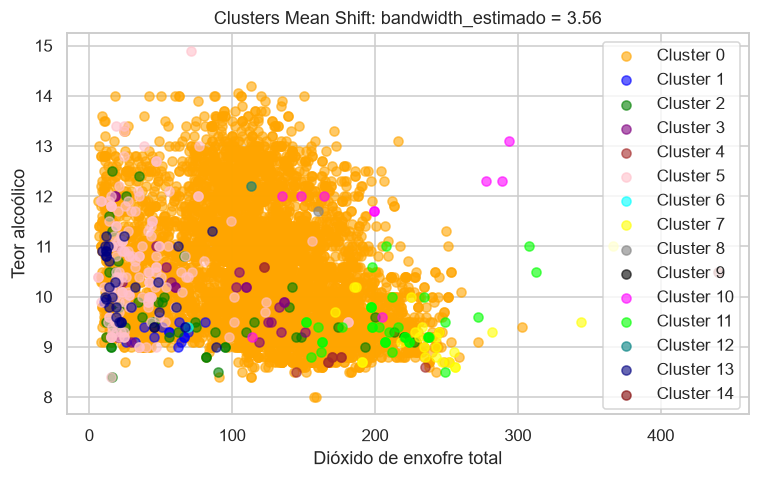

In [84]:
fig = plt.figure()
palette = {
    (-1): "red",
    (0): "orange",
    (1): "blue",
    (2): "green",
    (3): "purple",
    (4): "brown",
    (5): "pink",
    (6): "cyan",
    (7): "yellow",
    (8): "gray",
    (9): "black",
    (10): "magenta",
    (11): "lime",
    (12): "teal",
    (13): "navy",
    (14): "maroon",

}

for label in np.unique(meanshift.labels_):
    cluster_df = vinho_meanshift[vinho_meanshift["cluster"] == label]

    plt.scatter(
            cluster_df["total_sulfur_dioxide"],
            cluster_df["alcohol"],
            color=palette.get(label, "gray"),
            alpha=0.6,
            label=f"Cluster {label}"
        )

plt.xlabel("Dióxido de enxofre total")
plt.ylabel("Teor alcoólico")
plt.title("Clusters Mean Shift: bandwidth_estimado = " + str(round(bandwidth_estimado, 2)))
plt.legend()
salvar(fig, "Clusters_MeanShift_Dioxido_Enxofre_x_Teor_Alcoolico")
plt.show()


Devido a densidade do cluster 0 ele também não conseguiu clusterizar de forma positiva.

In [85]:
meanshift_4 = MeanShift(bandwidth=4)
meanshift_4.fit(vinho_meanshift_scaled)

,"bandwidth bandwidth: float, default=NoneBandwidth used in the flat kernel.If not given, the bandwidth is estimated usingsklearn.cluster.estimate_bandwidth; see the documentation for thatfunction for hints on scalability (see also the Notes, below).",4
,"seeds seeds: array-like of shape (n_samples, n_features), default=NoneSeeds used to initialize kernels. If not set,the seeds are calculated by clustering.get_bin_seedswith bandwidth as the grid size and default values forother parameters.",None
,"bin_seeding bin_seeding: bool, default=FalseIf true, initial kernel locations are not locations of allpoints, but rather the location of the discretized version ofpoints, where points are binned onto a grid whose coarsenesscorresponds to the bandwidth. Setting this option to True will speedup the algorithm because fewer seeds will be initialized.The default value is False.Ignored if seeds argument is not None.",False
,"min_bin_freq min_bin_freq: int, default=1To speed up the algorithm, accept only those bins with at leastmin_bin_freq points as seeds.",1
,"cluster_all cluster_all: bool, default=TrueIf true, then all points are clustered, even those orphans that arenot within any kernel. Orphans are assigned to the nearest kernel.If false, then orphans are given cluster label -1.",True
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. The following tasks benefitfrom the parallelization:- The search of nearest neighbors for bandwidth estimation and label assignments. See the details in the docstring of the ``NearestNeighbors`` class.- Hill-climbing optimization for all seeds.See :term:`Glossary <n_jobs>` for more details.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"max_iter max_iter: int, default=300Maximum number of iterations, per seed point before the clusteringoperation terminates (for that seed point), if has not converged yet... versionadded:: 0.22",300
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers.","ndarray[float64](8, 12)","[[-0.18,-0.23,-0.02,...,-0.19, 0.02, 0.04], [ 0.85, 1.24, 1.33,..., 4.3 ,-0.94,-0.5 ], [ 1.53, 1.1 , 4.69,..., 9.87,-0.92,-2.08], ..., [ 0.3 ,-0.54, 6.27,...,-0.68, 2.19, 0.21], [ 0.14,-0.85, 9.23,..., 0.13, 1.43, 0.21], [-0.86,-0.48,-0.47,..., 0.73, 0.01,-3.23]]"
"labels_ labels_: ndarray of shape (n_samples,)Labels of each point.","ndarray[int64](6497,)","[0,0,0,...,0,0,0]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,12


In [86]:
vinho_meanshift_4 = vinho_meanshift.copy()
vinho_meanshift_4['cluster'] = meanshift_4.labels_
vinho_meanshift_4.head()

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,cluster
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,0
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0


In [87]:
vinho_meanshift_4['cluster'].value_counts().sort_index()

cluster
0    6443
1      39
2       1
3       1
4       1
5      10
6       1
7       1
Name: count, dtype: int64

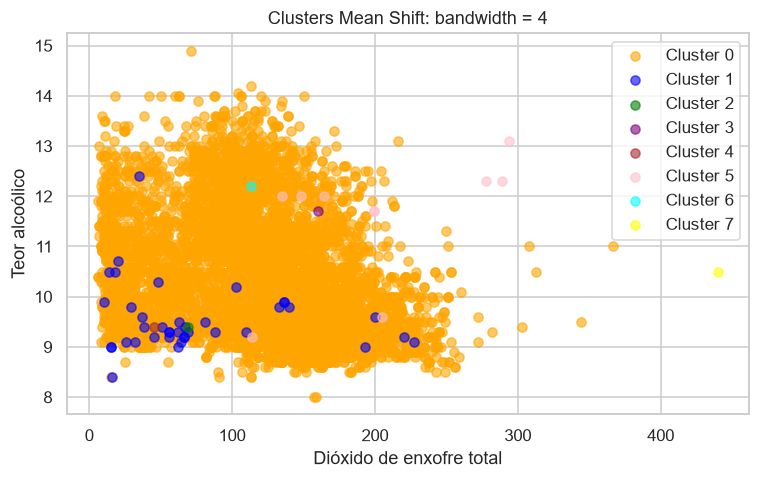

In [88]:
fig = plt.figure()
palette = {
    (-1): "red",
    (0): "orange",
    (1): "blue",
    (2): "green",
    (3): "purple",
    (4): "brown",
    (5): "pink",
    (6): "cyan",
    (7): "yellow",

}

for label in np.unique(meanshift_4.labels_):
    cluster_df = vinho_meanshift_4[vinho_meanshift_4["cluster"] == label]

    plt.scatter(
            cluster_df["total_sulfur_dioxide"],
            cluster_df["alcohol"],
            color=palette.get(label, "gray"),
            alpha=0.6,
            label=f"Cluster {label}"
        )

plt.xlabel("Dióxido de enxofre total")
plt.ylabel("Teor alcoólico")
plt.title("Clusters Mean Shift: bandwidth = " + str(4))
plt.legend()
salvar(fig, "Clusters_MeanShift_bandwidth4_Dioxido_Enxofre_x_Teor_Alcoolico")
plt.show()


Não houve melhora com um valor maior. Vamos tentar diminuir o bandwith

In [89]:
meanshift_2 = MeanShift(bandwidth=2)
meanshift_2.fit(vinho_meanshift_scaled)


,"bandwidth bandwidth: float, default=NoneBandwidth used in the flat kernel.If not given, the bandwidth is estimated usingsklearn.cluster.estimate_bandwidth; see the documentation for thatfunction for hints on scalability (see also the Notes, below).",2
,"seeds seeds: array-like of shape (n_samples, n_features), default=NoneSeeds used to initialize kernels. If not set,the seeds are calculated by clustering.get_bin_seedswith bandwidth as the grid size and default values forother parameters.",None
,"bin_seeding bin_seeding: bool, default=FalseIf true, initial kernel locations are not locations of allpoints, but rather the location of the discretized version ofpoints, where points are binned onto a grid whose coarsenesscorresponds to the bandwidth. Setting this option to True will speedup the algorithm because fewer seeds will be initialized.The default value is False.Ignored if seeds argument is not None.",False
,"min_bin_freq min_bin_freq: int, default=1To speed up the algorithm, accept only those bins with at leastmin_bin_freq points as seeds.",1
,"cluster_all cluster_all: bool, default=TrueIf true, then all points are clustered, even those orphans that arenot within any kernel. Orphans are assigned to the nearest kernel.If false, then orphans are given cluster label -1.",True
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. The following tasks benefitfrom the parallelization:- The search of nearest neighbors for bandwidth estimation and label assignments. See the details in the docstring of the ``NearestNeighbors`` class.- Hill-climbing optimization for all seeds.See :term:`Glossary <n_jobs>` for more details.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"max_iter max_iter: int, default=300Maximum number of iterations, per seed point before the clusteringoperation terminates (for that seed point), if has not converged yet... versionadded:: 0.22",300
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers.","ndarray[float64](200, 12)","[[-0.45,-0.52, 0.01,...,-0.35, 0.87, 0.54], [-0.35,-0.46,-0.12,...,-0.36,-0.43,-0.26], [ 0.16, 1.51,-1.36,..., 0.37,-0.53,-0.46], ..., [-2.33,-0.76,-0.61,...,-0.61,-2.09,-3.23], [-2.33,-1.03, 0.28,..., 2.41, 1.26, 1.35], [-2.63,-0.18,-2.06,...,-0.61, 1.6 , 0.21]]"
"labels_ labels_: ndarray of shape (n_samples,)Labels of each point.","ndarray[int64](6497,)","[2,2,2,...,1,0,0]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,12


In [90]:
vinho_meanshift_2 = vinho_meanshift.copy()
vinho_meanshift_2['cluster'] = meanshift_2.labels_
vinho_meanshift_2.head()

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,cluster
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,2
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,2
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,4
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,2


In [91]:
vinho_meanshift_2['cluster'].value_counts().sort_index()

cluster
0      1625
1      1843
2       708
3       313
4       226
       ... 
195       5
196       2
197       2
198       5
199       4
Name: count, Length: 200, dtype: int64

Com ele igual a 2 fez 200 clusters! Melhor tentar com 3

In [92]:
meanshift_3 = MeanShift(bandwidth=3)
meanshift_3.fit(vinho_meanshift_scaled)

,"bandwidth bandwidth: float, default=NoneBandwidth used in the flat kernel.If not given, the bandwidth is estimated usingsklearn.cluster.estimate_bandwidth; see the documentation for thatfunction for hints on scalability (see also the Notes, below).",3
,"seeds seeds: array-like of shape (n_samples, n_features), default=NoneSeeds used to initialize kernels. If not set,the seeds are calculated by clustering.get_bin_seedswith bandwidth as the grid size and default values forother parameters.",None
,"bin_seeding bin_seeding: bool, default=FalseIf true, initial kernel locations are not locations of allpoints, but rather the location of the discretized version ofpoints, where points are binned onto a grid whose coarsenesscorresponds to the bandwidth. Setting this option to True will speedup the algorithm because fewer seeds will be initialized.The default value is False.Ignored if seeds argument is not None.",False
,"min_bin_freq min_bin_freq: int, default=1To speed up the algorithm, accept only those bins with at leastmin_bin_freq points as seeds.",1
,"cluster_all cluster_all: bool, default=TrueIf true, then all points are clustered, even those orphans that arenot within any kernel. Orphans are assigned to the nearest kernel.If false, then orphans are given cluster label -1.",True
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. The following tasks benefitfrom the parallelization:- The search of nearest neighbors for bandwidth estimation and label assignments. See the details in the docstring of the ``NearestNeighbors`` class.- Hill-climbing optimization for all seeds.See :term:`Glossary <n_jobs>` for more details.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"max_iter max_iter: int, default=300Maximum number of iterations, per seed point before the clusteringoperation terminates (for that seed point), if has not converged yet... versionadded:: 0.22",300
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers.","ndarray[float64](34, 12)","[[-0.31,-0.46,-0. ,...,-0.32, 0.21, 0.15], [ 0.81, 1.23, 1.55,..., 4.42,-1.06,-0.61], [ 0.37, 1.24, 0.63,..., 0.42,-1.04,-1.32], ..., [-0.86,-0.48,-0.47,..., 0.73, 0.01,-3.23], [-1.01,-0.73, 0.9 ,...,-1.22, 1.94,-0.94], [-1.09, 4.07, 2.35,..., 0.46, 0.85, 0.21]]"
"labels_ labels_: ndarray of shape (n_samples,)Labels of each point.","ndarray[int64](6497,)","[0,0,0,...,0,0,0]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,12


In [93]:
vinho_meanshift_3 = vinho_meanshift.copy()
vinho_meanshift_3['cluster'] = meanshift_3.labels_
vinho_meanshift_3.head()

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,cluster
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,11
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0


In [94]:
vinho_meanshift_3['cluster'].value_counts().sort_index()

cluster
0     5693
1       17
2       51
3       22
4       11
5      162
6        3
7       18
8       41
9       15
10      15
11      79
12      61
13       1
14      50
15       1
16       1
17       1
18      53
19      16
20       1
21      27
22       1
23      32
24       4
25       3
26      31
27       1
28       2
29      13
30       4
31       1
32      13
33      53
Name: count, dtype: int64

34 clusters é mais razoável mas continua a mesma situação de clusters desbalanceados, com grande densidade no cluster 0

## Questão 6 - Conclusão

* Compare os resultados com os obtidos com os 4 algoritmos e relate sua opinião sobre qual algoritmo obteve melhor performance e porquê.



Na minha opinião, K-means e HAC foram os métodos que apresentaram os resultados mais claros. Os dois separaram principalmente os vinhos brancos e tintos em grupos diferentes, embora a cor não tenha sido usada na clusterização. O HAC agrupou os tintos de forma um pouco mais concentrada, enquanto o K-means formou um grupo de brancos ligeiramente mais uniforme. Por isso, considero que os dois tiveram resultados parecidos, com pequenas diferenças, em vez de afirmar que o HAC foi melhor no geral.

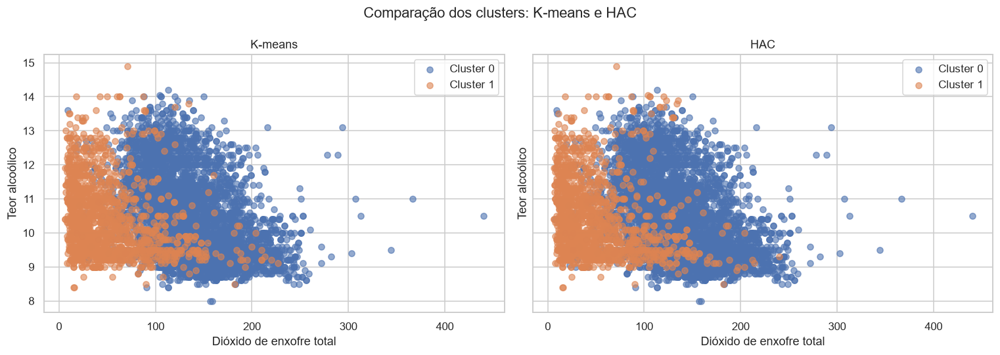

In [95]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)

# K-means: rótulos calculados com dados padronizados,
# mas o gráfico usa os valores originais.
for label in np.unique(km_2.labels_):
    grupo = vinhos_dataframe.iloc[km_2.labels_ == label]

    ax[0].scatter(
        grupo["total_sulfur_dioxide"],
        grupo["alcohol"],
        label=f"Cluster {label}",
        alpha=0.6
    )

ax[0].set_title("K-means")
ax[0].set_xlabel("Dióxido de enxofre total")
ax[0].set_ylabel("Teor alcoólico")
ax[0].legend()

# HAC: mostra os mesmos valores originais.
vinho_hac = vinhos_dataframe.copy()
vinho_hac["cluster"] = labels_todos

for label in np.unique(labels_todos):
    grupo = vinho_hac[vinho_hac["cluster"] == label]

    ax[1].scatter(
        grupo["total_sulfur_dioxide"],
        grupo["alcohol"],
        label=f"Cluster {label}",
        alpha=0.6
    )

ax[1].set_title("HAC")
ax[1].set_xlabel("Dióxido de enxofre total")
ax[1].set_ylabel("Teor alcoólico")
ax[1].legend()

fig.suptitle("Comparação dos clusters: K-means e HAC")
plt.tight_layout()
salvar(fig, "Comparacao_Clusters_KMeans_HAC_Dioxido_Enxofre_x_Teor_Alcoolico")
plt.show()


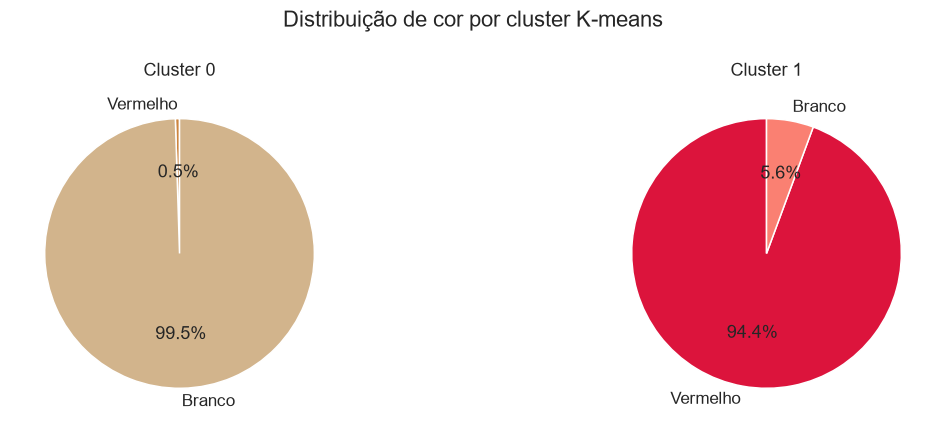

<Figure size 880x495 with 0 Axes>

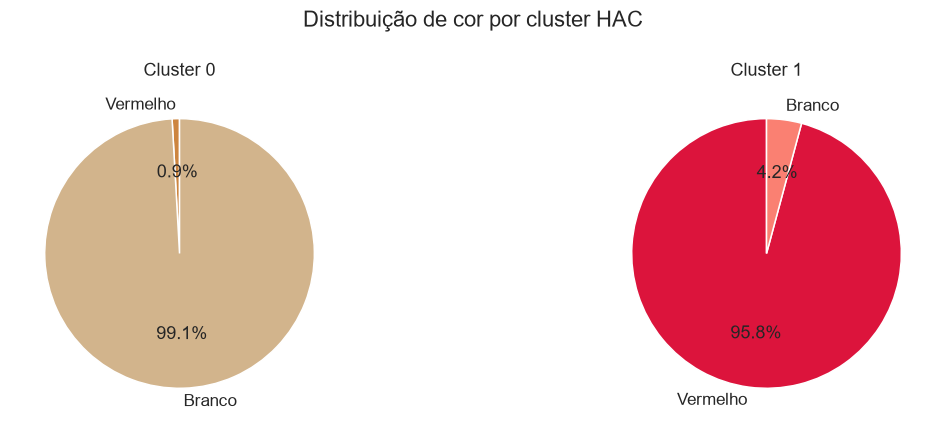

<Figure size 880x495 with 0 Axes>

In [96]:
num_branco_0 = vinhos_clusterizados[(vinhos_clusterizados['color'] == 'white') & (vinhos_clusterizados['cluster'] == 0)].shape[0]
num_branco_1 = vinhos_clusterizados[(vinhos_clusterizados['color'] == 'white') & (vinhos_clusterizados['cluster'] == 1)].shape[0]

num_vermelho_0 = vinhos_clusterizados[(vinhos_clusterizados['color'] == 'red') & (vinhos_clusterizados['cluster'] == 0)].shape[0]
num_vermelho_1 = vinhos_clusterizados[(vinhos_clusterizados['color'] == 'red') & (vinhos_clusterizados['cluster'] == 1)].shape[0]

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

labels_cluster_0 = ["Vermelho", "Branco"]
sizes_cluster_0 = [num_vermelho_0, num_branco_0]
colors_cluster_0 = ["peru", "tan"]

labels_cluster_1 = ["Vermelho", "Branco"]
sizes_cluster_1 = [num_vermelho_1, num_branco_1]
colors_cluster_1 = ["crimson", "salmon"]

ax[0].pie(
    sizes_cluster_0,
    labels=labels_cluster_0,
    autopct="%1.1f%%",
    startangle=90,
    colors=colors_cluster_0
)
ax[0].set_title("Cluster 0")

ax[1].pie(
    sizes_cluster_1,
    labels=labels_cluster_1,
    autopct="%1.1f%%",
    startangle=90,
    colors=colors_cluster_1
)
ax[1].set_title("Cluster 1")

plt.suptitle("Distribuição de cor por cluster K-means")
plt.tight_layout()
plt.show()
plt.savefig("Distribuicao_de_cor_por_cluster_K-means.png", dpi=300, bbox_inches="tight")

num_branco_0 = vinhos_clusterizados[(vinho_hac['color'] == 'white') & (vinho_hac['cluster'] == 0)].shape[0]
num_branco_1 = vinhos_clusterizados[(vinho_hac['color'] == 'white') & (vinho_hac['cluster'] == 1)].shape[0]

num_vermelho_0 = vinhos_clusterizados[(vinho_hac['color'] == 'red') & (vinho_hac['cluster'] == 0)].shape[0]
num_vermelho_1 = vinhos_clusterizados[(vinho_hac['color'] == 'red') & (vinho_hac['cluster'] == 1)].shape[0]

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

labels_cluster_0 = ["Vermelho", "Branco"]
sizes_cluster_0 = [num_vermelho_0, num_branco_0]
colors_cluster_0 = ["peru", "tan"]

labels_cluster_1 = ["Vermelho", "Branco"]
sizes_cluster_1 = [num_vermelho_1, num_branco_1]
colors_cluster_1 = ["crimson", "salmon"]

ax[0].pie(
    sizes_cluster_0,
    labels=labels_cluster_0,
    autopct="%1.1f%%",
    startangle=90,
    colors=colors_cluster_0
)
ax[0].set_title("Cluster 0")

ax[1].pie(
    sizes_cluster_1,
    labels=labels_cluster_1,
    autopct="%1.1f%%",
    startangle=90,
    colors=colors_cluster_1
)
ax[1].set_title("Cluster 1")

plt.suptitle("Distribuição de cor por cluster HAC")
plt.tight_layout()
plt.show()
plt.savefig("Distribuicao_de_cor_por_cluster_HAC.png", dpi=300, bbox_inches="tight")

## Exercício 2

* Escolha uma imagem colorida de sua preferência. Não se esqueça de me enviar a imagem.

In [97]:
import numpy as np
import itertools
import pandas as pd
import matplotlib.image as mpimg
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans




caminho = "./imagem/the_ball_of_yarn.jpg"
img = mpimg.imread(caminho)


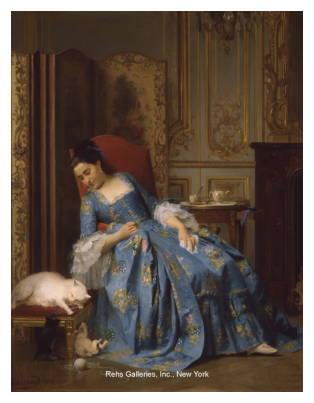

In [98]:
plt.imshow(img)
plt.axis("off")
plt.show()

In [99]:
pixels = img.reshape(-1, 3)
pixels.shape

(1725000, 3)

 ## Questão 1

 Faça a segmentação desta imagem utilizando K means com 2 e 6 clusters e plote essas imagens.

In [100]:
kmeans = KMeans(n_clusters=2, random_state=10)
kmeans.fit(pixels)


,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",2
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",10
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](2, 3)","[

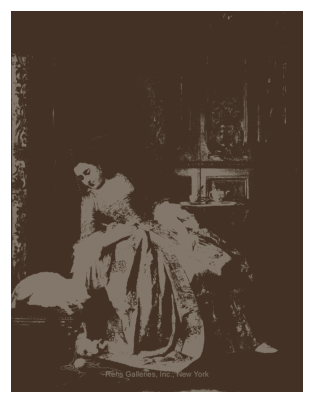

In [101]:
fig = plt.figure()
segmented_img = kmeans.cluster_centers_[kmeans.labels_].reshape(img.shape)

plt.imshow(segmented_img / 255.0)
plt.axis("off")
salvar(fig, "Segmentacao_KMeans_2_cores")
plt.show()


In [102]:
kmeans3 = KMeans(n_clusters=3, random_state=10)
kmeans3.fit(pixels)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",3
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",10
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](3, 3)","[

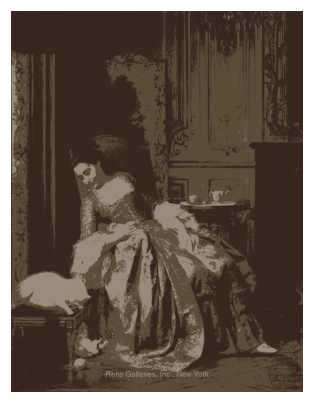

In [103]:
fig = plt.figure()
segmented_img_3 = kmeans3.cluster_centers_[kmeans3.labels_].reshape(img.shape)

plt.imshow(segmented_img_3 / 255.0)
plt.axis("off")
salvar(fig, "Segmentacao_KMeans_3_cores")
plt.show()


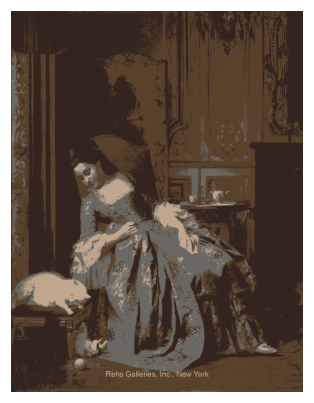

In [104]:
fig = plt.figure()
kmeans4 = KMeans(n_clusters=4, random_state=10)
kmeans4.fit(pixels)
segmented_img_4 = kmeans4.cluster_centers_[kmeans4.labels_].reshape(img.shape)

plt.imshow(segmented_img_4 / 255.0)
plt.axis("off")
salvar(fig, "Segmentacao_KMeans_4_cores")
plt.show()


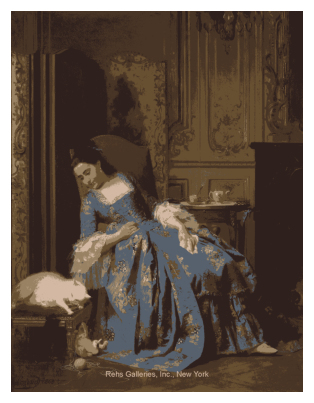

In [105]:
fig = plt.figure()
kmeans6 = KMeans(n_clusters=6, random_state=10)
kmeans6.fit(pixels)
segmented_img_6 = kmeans6.cluster_centers_[kmeans6.labels_].reshape(img.shape)

plt.imshow(segmented_img_6 / 255.0)
plt.axis("off")
salvar(fig, "Segmentacao_KMeans_6_cores")
plt.show()


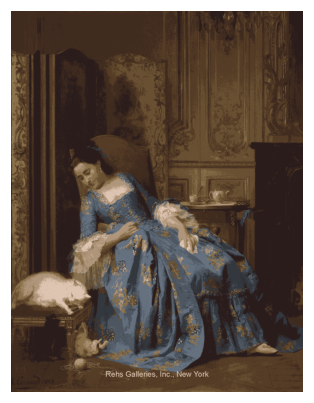

In [106]:
fig = plt.figure()
kmeans10 = KMeans(n_clusters=10, random_state=10)
kmeans10.fit(pixels)
segmented_img_10 = kmeans10.cluster_centers_[kmeans10.labels_].reshape(img.shape)

plt.imshow(segmented_img_10 / 255.0)
plt.axis("off")
salvar(fig, "Segmentacao_KMeans_10_cores")
plt.show()


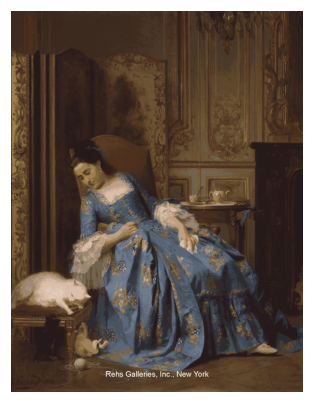

In [107]:
fig = plt.figure()
kmeans20 = KMeans(n_clusters=20, random_state=10)
kmeans20.fit(pixels)
segmented_img_20 = kmeans20.cluster_centers_[kmeans20.labels_].reshape(img.shape)
plt.imshow(segmented_img_20 / 255.0)
plt.axis("off")
salvar(fig, "Segmentacao_KMeans_20_cores")
plt.show()


 ## Questão 2

 Faça a segmentação desta imagem utilizando HAC com 2 e 6 clusters e plote essas imagens.

Tentei fazer com a imagem original mas o código abaixo dá erro

Unable to allocate 10.8 TiB for an array with shape (1487811637500,) and data type float64

Ele tenta fazer um array com 10.8 terabytes! Tem que diminuir a quantidade de pixels na imagem.

In [108]:
#from sklearn.cluster import AgglomerativeClustering
#import numpy as np
#import matplotlib.pyplot as plt

#pixels = img.reshape(-1, 3)
#pixels.shape

#hac_image = AgglomerativeClustering(n_clusters=2, linkage="ward")
#rotulos = hac_image.fit_predict(pixels)

# Cor média de cada um dos 2 clusters
#cores = np.array([
#    pixels[rotulos == i].mean(axis=0)
#    for i in range(2)
#])

# Reconstrói a imagem usando a cor média do cluster de cada pixel
#segmented_img_hac_2 = cores[rotulos].reshape(altura, largura, canais)

#plt.imshow(segmented_img_hac_2)
#plt.title("HAC — 2 clusters")
#plt.axis("off")
#plt.show()

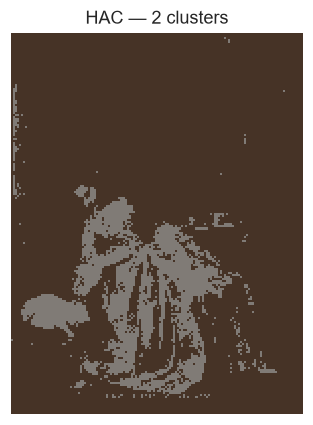

In [109]:
fig = plt.figure()
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import AgglomerativeClustering

# Reduz a imagem para no máximo 200 pixels na maior dimensão.
# Isso limita a quantidade de pixels que o HAC precisa agrupar.
passo = max(1, int(np.ceil(max(img.shape[:2]) / 200)))
img_reduzida = img[::passo, ::passo]

# Garante que a imagem tenha 3 canais RGB.
if img_reduzida.ndim == 2:
    img_reduzida = np.repeat(img_reduzida[:, :, None], 3, axis=2)
elif img_reduzida.shape[2] == 4:
    img_reduzida = img_reduzida[:, :, :3]

img_reduzida = img_reduzida.astype(np.float32)
if img_reduzida.max() > 1:
    img_reduzida /= 255.0

altura, largura, canais = img_reduzida.shape
pixels_reduzido = img_reduzida.reshape(-1, canais)

hac_image = AgglomerativeClustering(n_clusters=2, linkage="ward")
rotulos = hac_image.fit_predict(pixels_reduzido)

cores = np.array([
    pixels_reduzido[rotulos == i].mean(axis=0)
    for i in range(2)
])

segmented_img_hac_2 = cores[rotulos].reshape(altura, largura, canais)

plt.imshow(segmented_img_hac_2, interpolation="nearest")
plt.title("HAC — 2 clusters")
plt.axis("off")
salvar(fig, "Segmentacao_HAC_2_cores")
plt.show()


Com 200 pixels a qualidade da imagem diminui, e o algoritmo até demora para executar. Vamos tentar com 6 clusters

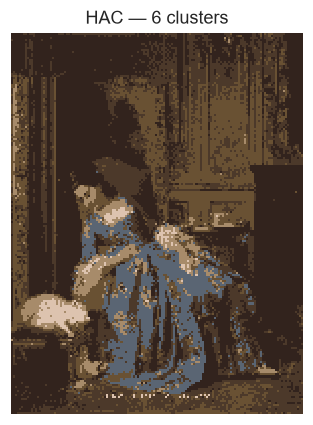

In [110]:
fig = plt.figure()
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import AgglomerativeClustering

# Número de grupos usados tanto pelo HAC quanto no cálculo das cores.
n_clusters = 6

# Reduz a imagem para no máximo 200 pixels na maior dimensão.
passo = max(1, int(np.ceil(max(img.shape[:2]) / 200)))
img_reduzida = img[::passo, ::passo]

# Garante que a imagem tenha 3 canais RGB.
if img_reduzida.ndim == 2:
    img_reduzida = np.repeat(img_reduzida[:, :, None], 3, axis=2)
elif img_reduzida.shape[2] == 4:
    img_reduzida = img_reduzida[:, :, :3]

# Converte os pixels para valores entre 0 e 1.
img_reduzida = img_reduzida.astype(np.float32)
if img_reduzida.max() > 1:
    img_reduzida /= 255.0

altura, largura, canais = img_reduzida.shape
pixels = img_reduzida.reshape(-1, canais)

# Agrupa os pixels em 6 clusters.
hac_image = AgglomerativeClustering(
    n_clusters=n_clusters,
    linkage="ward"
)
rotulos = hac_image.fit_predict(pixels)

# Calcula uma cor média para cada cluster.
cores = np.array([
    pixels[rotulos == i].mean(axis=0)
    for i in range(n_clusters)
])

# Substitui cada pixel pela cor média do cluster correspondente.
segmented_img_hac_2 = cores[rotulos].reshape(altura, largura, canais)

plt.imshow(segmented_img_hac_2, interpolation="nearest")
plt.title(f"HAC — {n_clusters} clusters")
plt.axis("off")
salvar(fig, f"Segmentacao_HAC_{n_clusters}_cores")
plt.show()


O resultado do K-means pareceu mais satisfatório neste teste. No HAC, foi necessário reduzir a resolução da imagem para viabilizar o processamento, o que também reduziu os detalhes. Como os métodos foram aplicados em resoluções diferentes, essa comparação não permite concluir que o K-means seja sempre melhor.

 ## Questão Bonus

Você consegue pensar em uma lógica para segmentar essa imagem utilizando os algoritmos DBSCAN e Meanshift?


A lógica seria considerar a cor e a posição de cada pixel na imagem. Assim, pixels com cores parecidas e próximos uns dos outros seriam agrupados, formando regiões segmentadas.

No DBSCAN, definiria uma distância entre os pixels e um número mínimo de vizinhos para formar um grupo. Os pixels que não se encaixassem em nenhum grupo seriam considerados ruído. Já o MeanShift procuraria regiões de maior concentração de pixels parecidos, sem precisar definir previamente o número de grupos.

Como os dois métodos podem ficar lentos com muitos pixels, talvez fosse necessário reduzir a resolução da imagem, assim como fiz com o HAC. Outra possibilidade seria dividir a imagem em partes, como quadrantes, e rodar o algoritmo em cada uma. Isso poderia deixar o processamento mais viável, embora as regiões encontradas nas bordas talvez não combinassem perfeitamente.